In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy import interpolate
from scipy.stats import gaussian_kde
import glob
import pickle
import matplotlib
import os
from numpy import correlate

from scipy.signal import coherence
from scipy.fft import fft, fftfreq


matplotlib.rcParams['font.size'] = 8.0
matplotlib.rcParams['pdf.fonttype'] = 42
mpl.rcParams['font.family'] = 'Arial'

In [2]:
Fs = 3e4
L = 600  # still 600 — used to trim upsampled to match p_spike
chunk_size = 210  # 7ms bins
out_path = './dataFolder/6_NaturalBehavior/Clipped_test/v3/CrossCor/'
os.makedirs(out_path, exist_ok=True)

out_fig = './dataFolder/Figures/4_NaturalBehavior/clipped/v3/CrossCor/'
os.makedirs(out_fig, exist_ok=True)

In [3]:
prediction_files = glob.glob('./dataFolder/6_NaturalBehavior/Clipped_test/v2/*_Prediction.pickle')

In [4]:
crosscor_results = {}
summary_rows = []

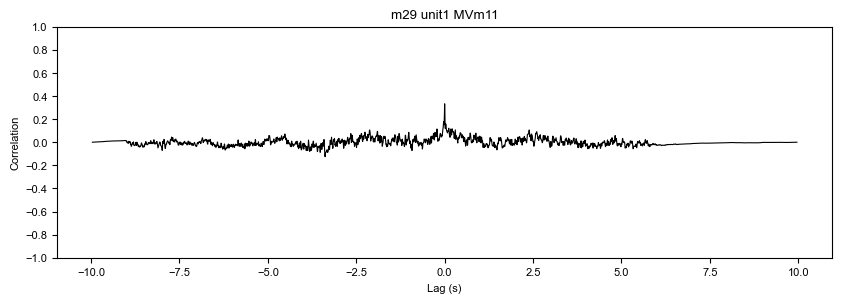

m29 unit1 MVm11: peak=0.333 at lag=0.0000s | at_zero=0.333


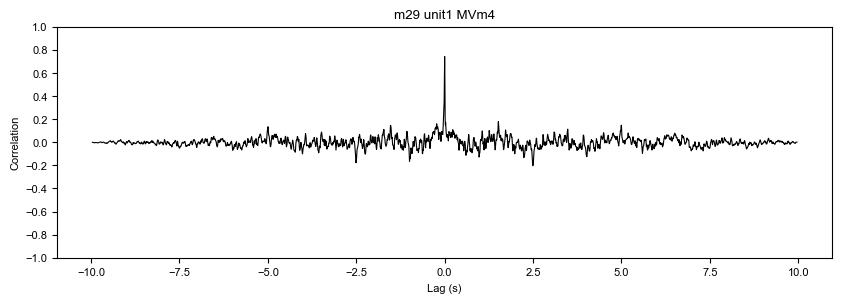

m29 unit1 MVm4: peak=0.742 at lag=0.0000s | at_zero=0.742


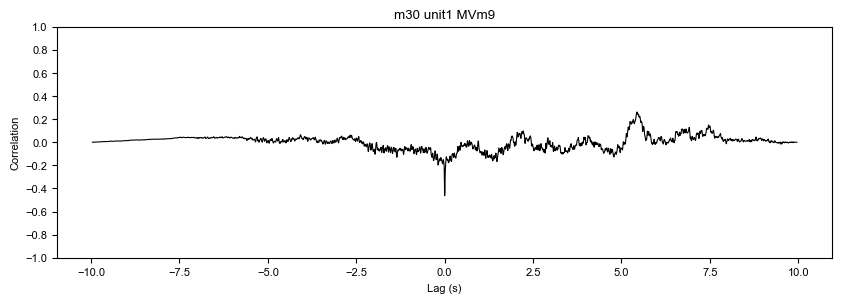

m30 unit1 MVm9: peak=-0.463 at lag=0.0000s | at_zero=-0.463


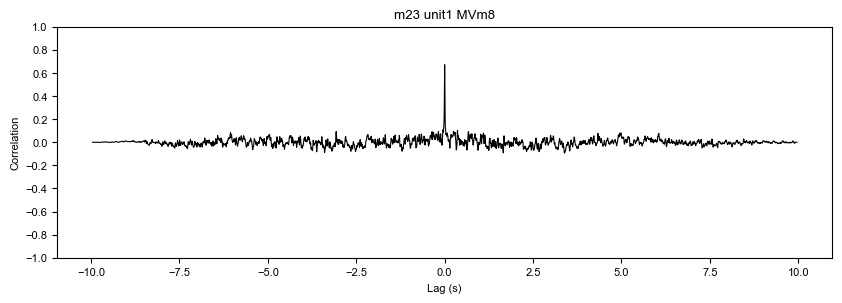

m23 unit1 MVm8: peak=0.671 at lag=0.0000s | at_zero=0.671


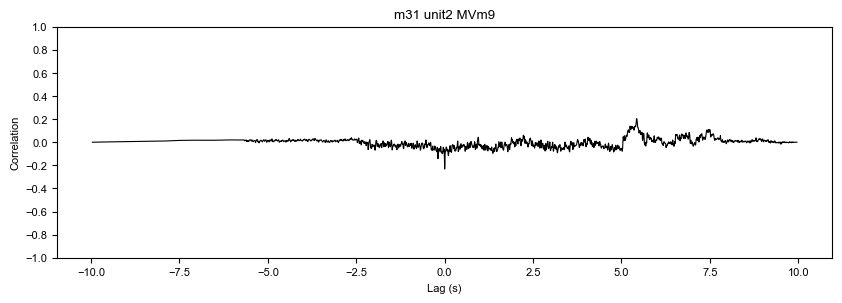

m31 unit2 MVm9: peak=-0.232 at lag=0.0000s | at_zero=-0.232


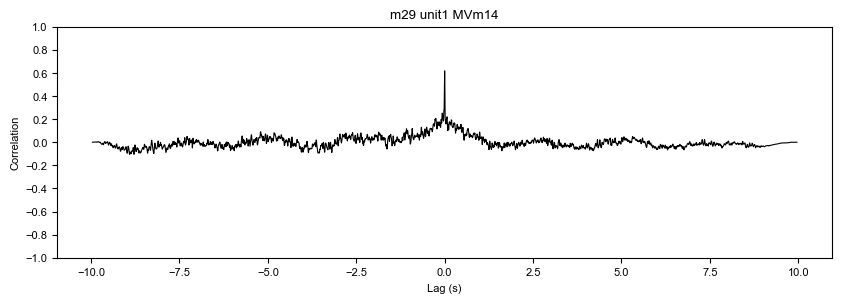

m29 unit1 MVm14: peak=0.618 at lag=0.0000s | at_zero=0.618


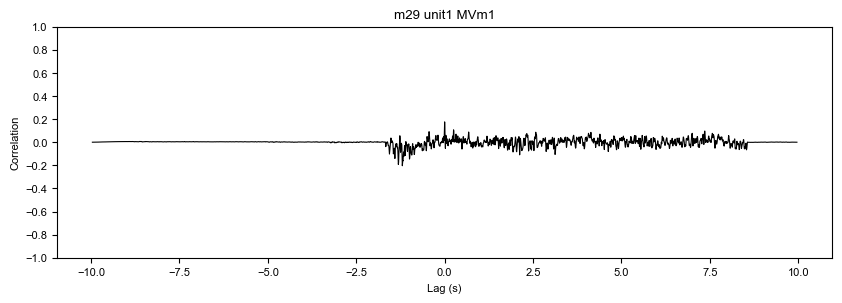

m29 unit1 MVm1: peak=-0.204 at lag=-1.1970s | at_zero=0.176


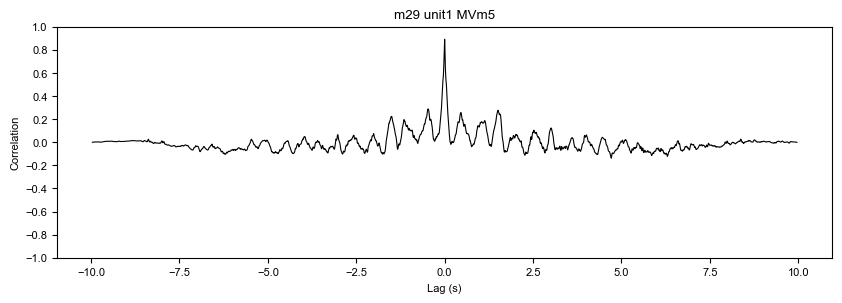

m29 unit1 MVm5: peak=0.891 at lag=0.0000s | at_zero=0.891


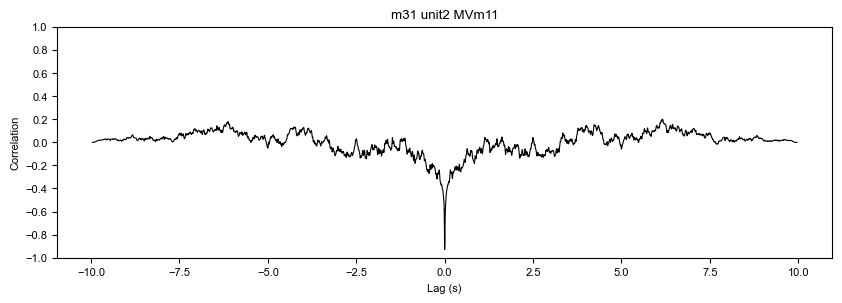

m31 unit2 MVm11: peak=-0.929 at lag=0.0000s | at_zero=-0.929


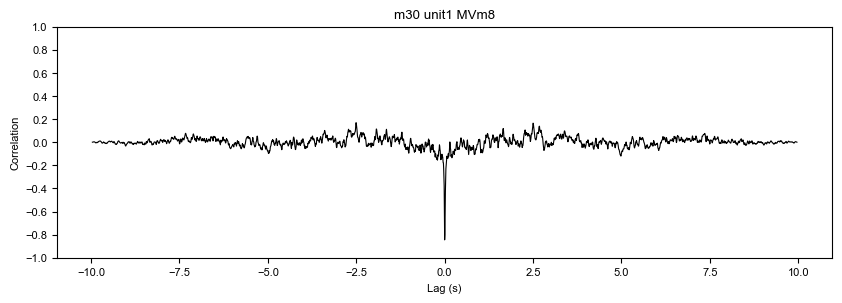

m30 unit1 MVm8: peak=-0.846 at lag=0.0000s | at_zero=-0.846


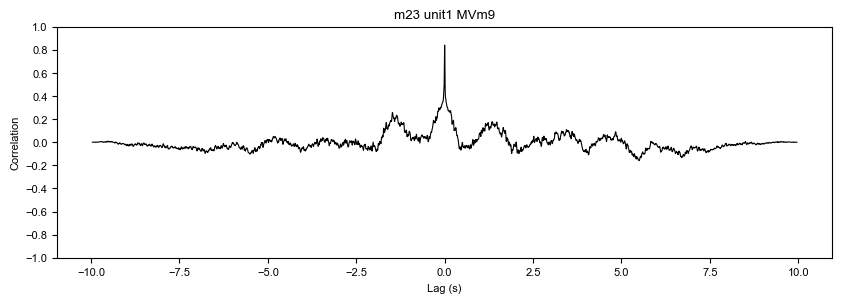

m23 unit1 MVm9: peak=0.841 at lag=0.0000s | at_zero=0.841


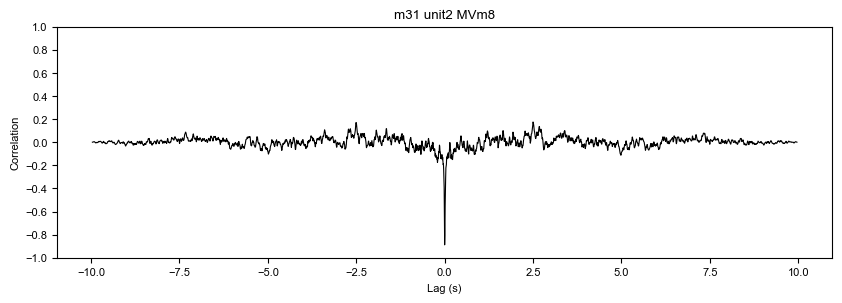

m31 unit2 MVm8: peak=-0.889 at lag=0.0000s | at_zero=-0.889


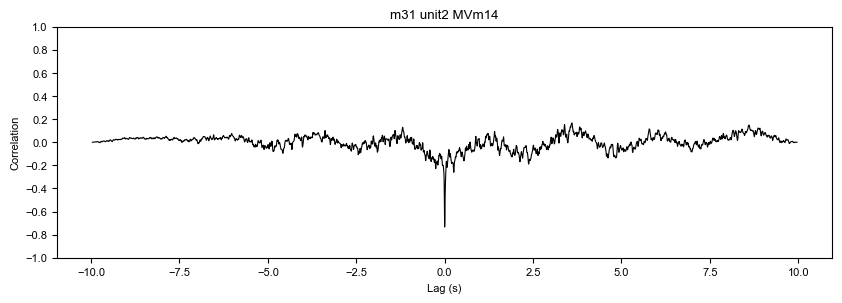

m31 unit2 MVm14: peak=-0.734 at lag=0.0000s | at_zero=-0.734


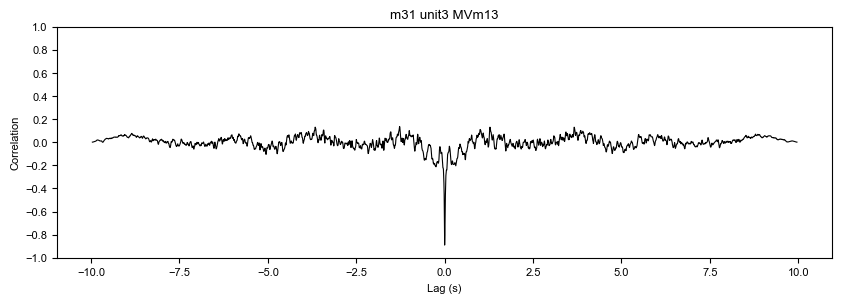

m31 unit3 MVm13: peak=-0.890 at lag=0.0000s | at_zero=-0.890


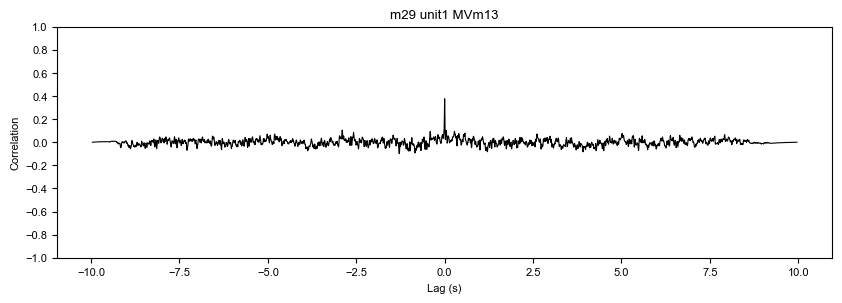

m29 unit1 MVm13: peak=0.376 at lag=0.0000s | at_zero=0.376


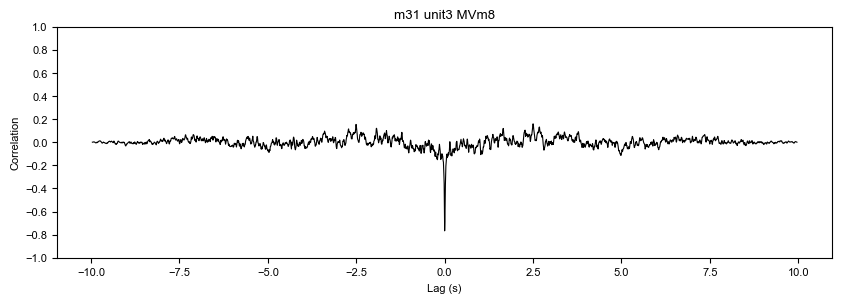

m31 unit3 MVm8: peak=-0.767 at lag=0.0000s | at_zero=-0.767


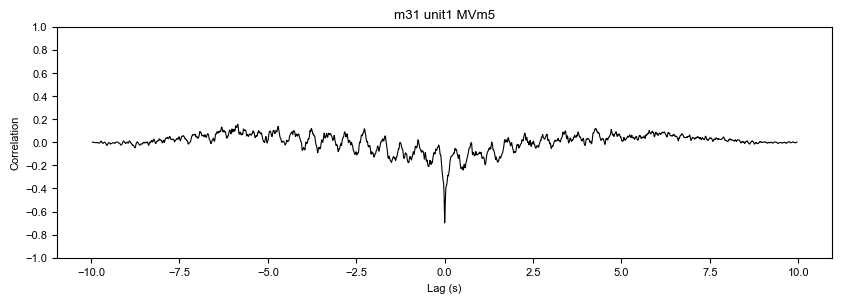

m31 unit1 MVm5: peak=-0.699 at lag=0.0000s | at_zero=-0.699


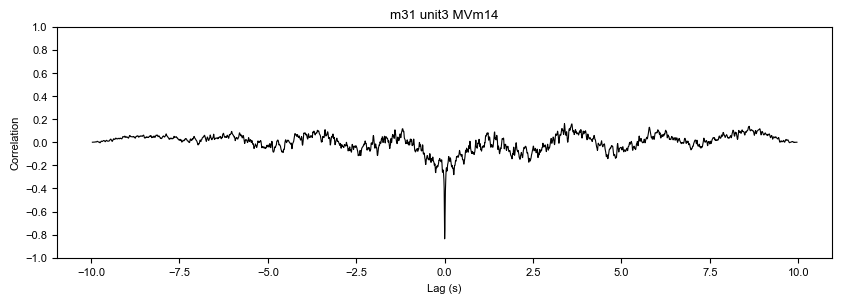

m31 unit3 MVm14: peak=-0.836 at lag=0.0000s | at_zero=-0.836


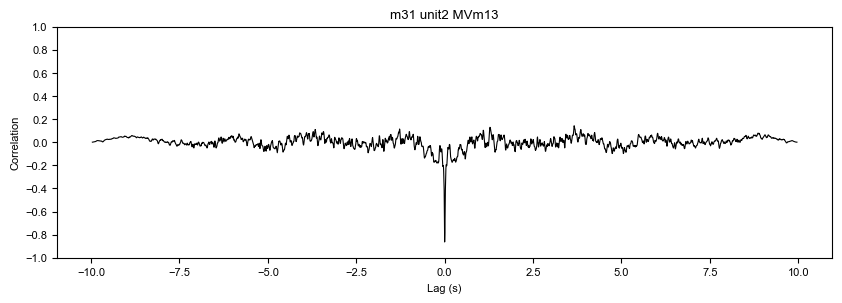

m31 unit2 MVm13: peak=-0.864 at lag=0.0000s | at_zero=-0.864


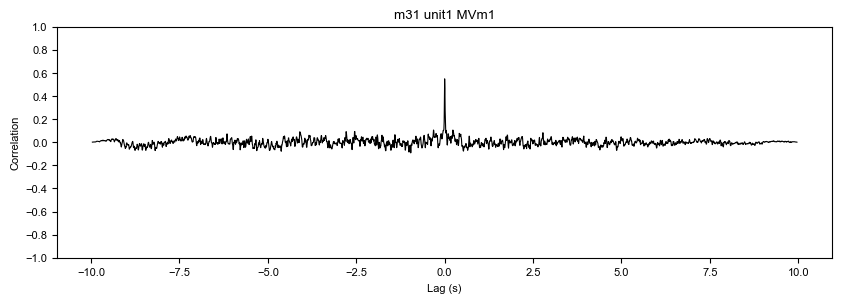

m31 unit1 MVm1: peak=0.549 at lag=0.0000s | at_zero=0.549


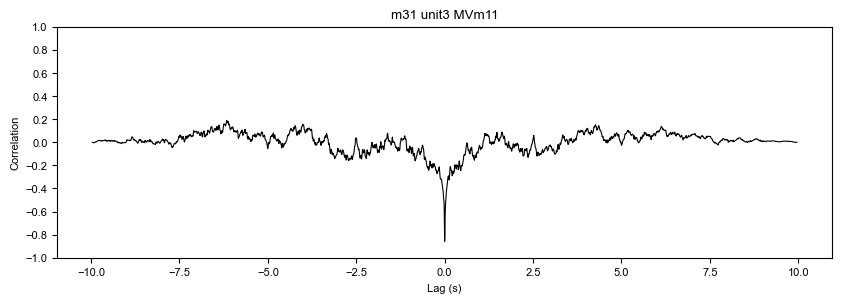

m31 unit3 MVm11: peak=-0.858 at lag=0.0000s | at_zero=-0.858


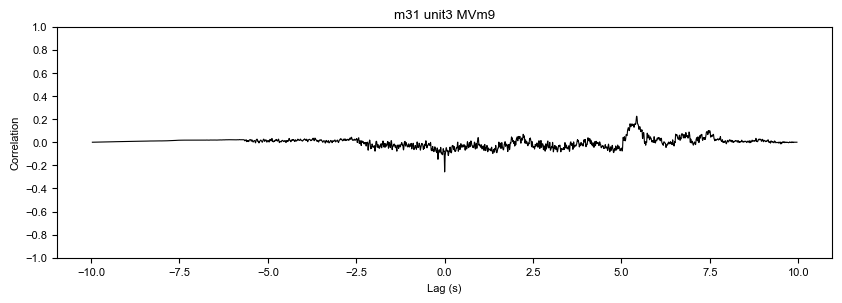

m31 unit3 MVm9: peak=-0.257 at lag=0.0000s | at_zero=-0.257


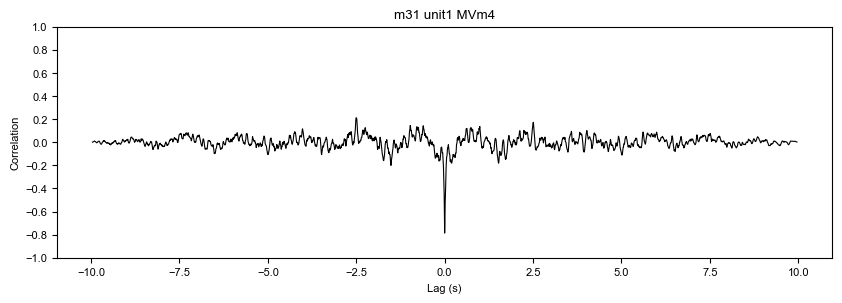

m31 unit1 MVm4: peak=-0.787 at lag=0.0000s | at_zero=-0.787


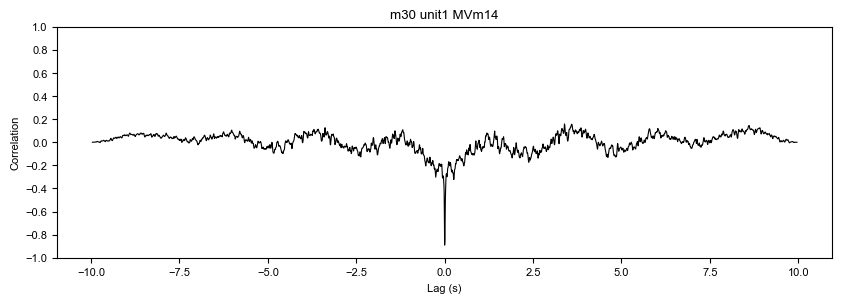

m30 unit1 MVm14: peak=-0.891 at lag=0.0000s | at_zero=-0.891


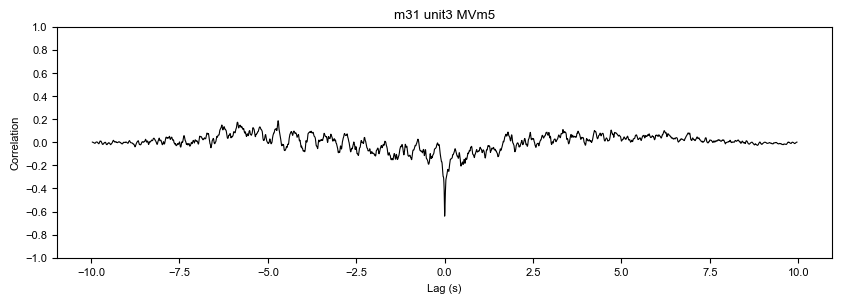

m31 unit3 MVm5: peak=-0.640 at lag=0.0000s | at_zero=-0.640


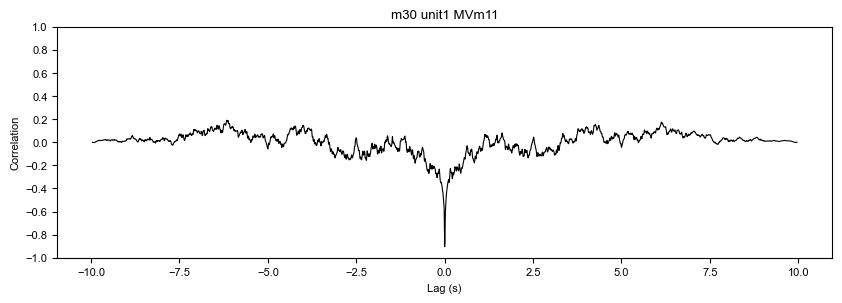

m30 unit1 MVm11: peak=-0.905 at lag=0.0000s | at_zero=-0.905


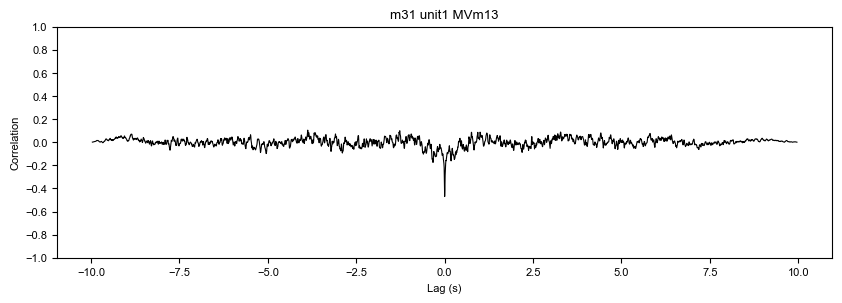

m31 unit1 MVm13: peak=-0.470 at lag=0.0000s | at_zero=-0.470


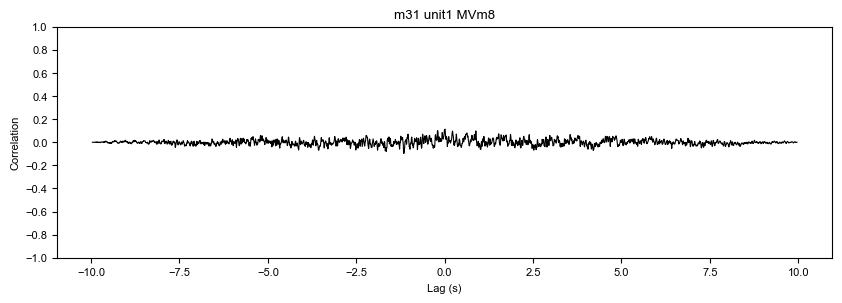

m31 unit1 MVm8: peak=0.113 at lag=0.0140s | at_zero=0.109


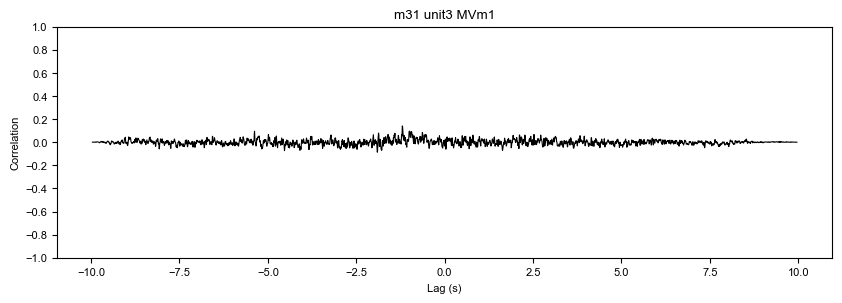

m31 unit3 MVm1: peak=0.141 at lag=-1.1970s | at_zero=-0.034


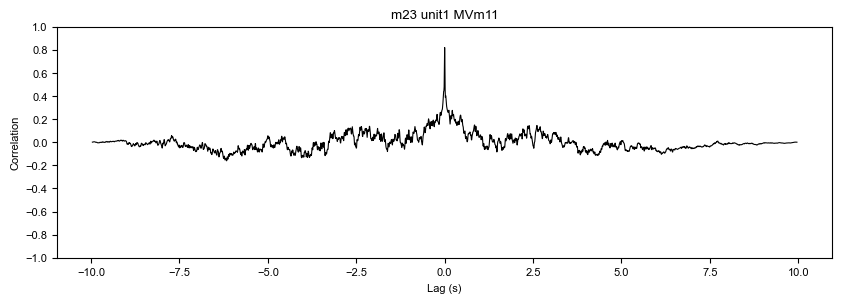

m23 unit1 MVm11: peak=0.820 at lag=0.0000s | at_zero=0.820


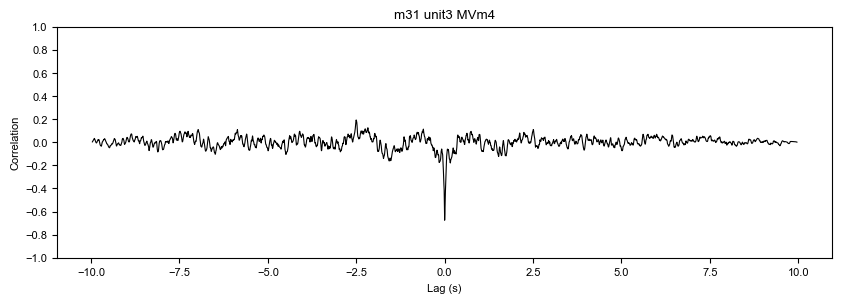

m31 unit3 MVm4: peak=-0.675 at lag=0.0000s | at_zero=-0.675


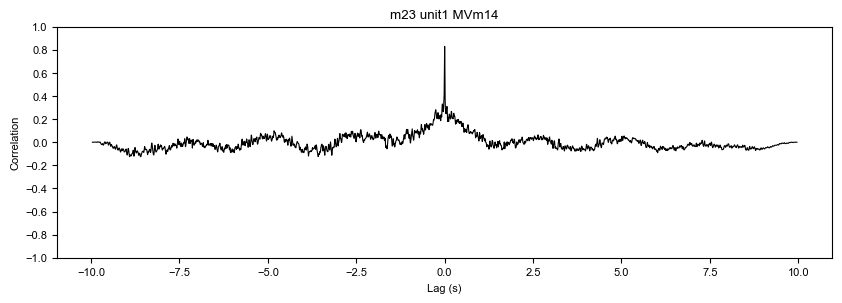

m23 unit1 MVm14: peak=0.830 at lag=0.0000s | at_zero=0.830


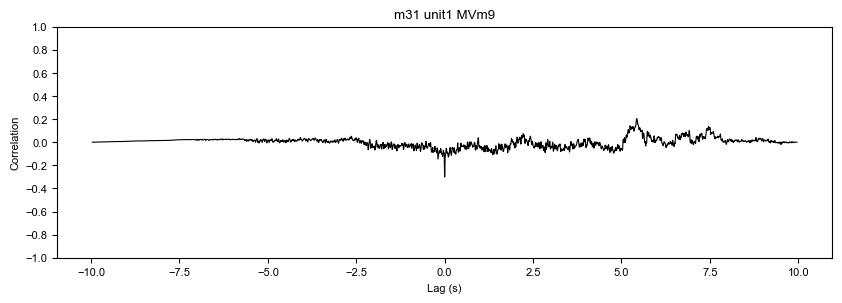

m31 unit1 MVm9: peak=-0.301 at lag=0.0000s | at_zero=-0.301


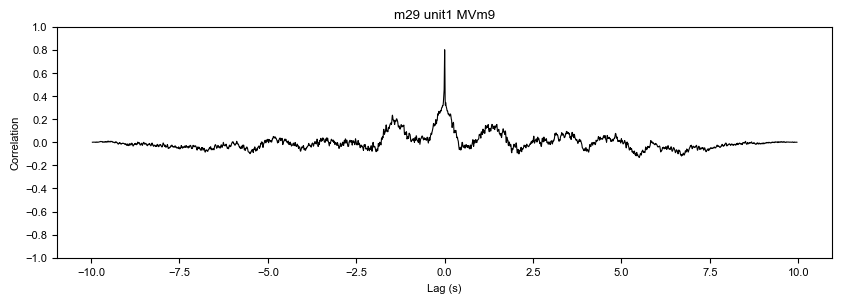

m29 unit1 MVm9: peak=0.801 at lag=0.0000s | at_zero=0.801


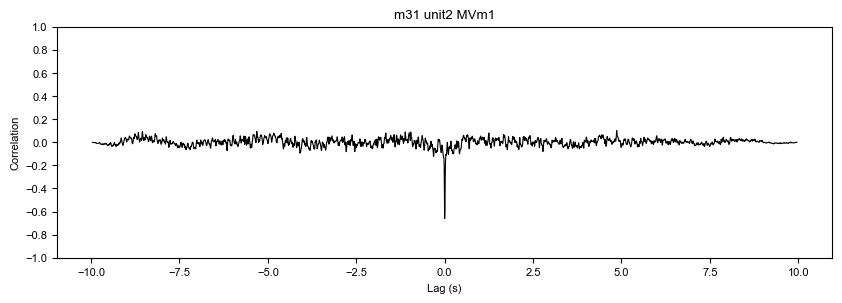

m31 unit2 MVm1: peak=-0.661 at lag=0.0000s | at_zero=-0.661


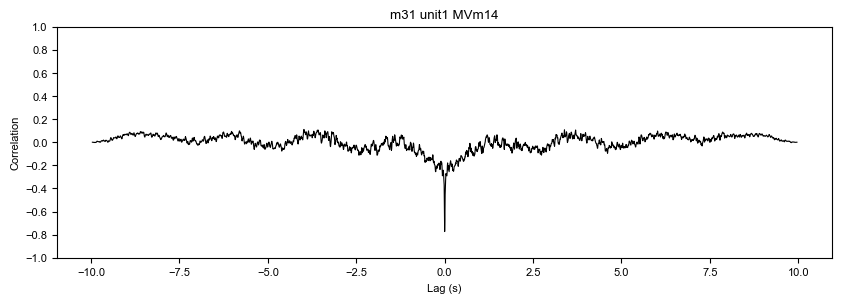

m31 unit1 MVm14: peak=-0.773 at lag=0.0000s | at_zero=-0.773


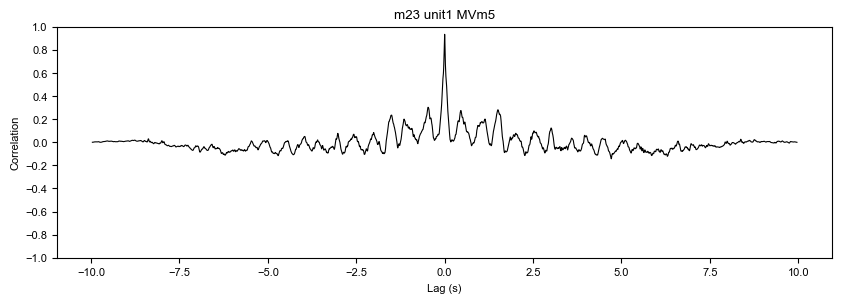

m23 unit1 MVm5: peak=0.934 at lag=0.0000s | at_zero=0.934


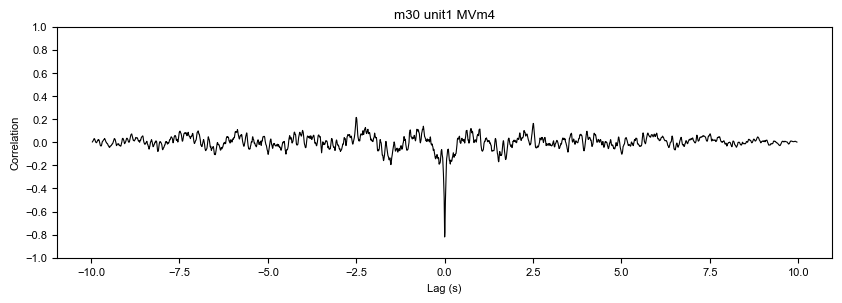

m30 unit1 MVm4: peak=-0.820 at lag=0.0000s | at_zero=-0.820


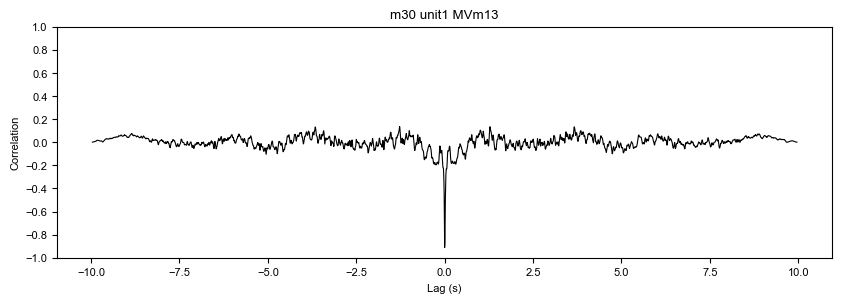

m30 unit1 MVm13: peak=-0.911 at lag=0.0000s | at_zero=-0.911


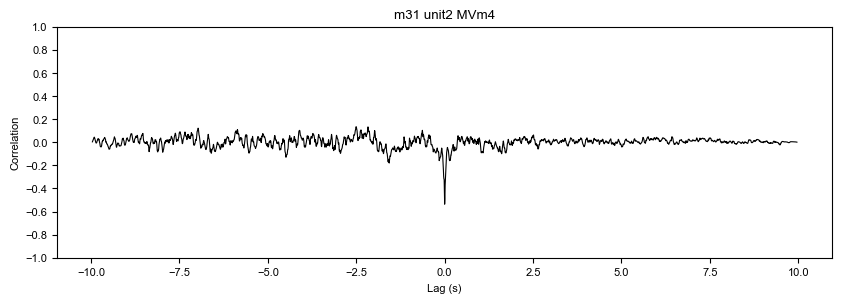

m31 unit2 MVm4: peak=-0.537 at lag=0.0000s | at_zero=-0.537


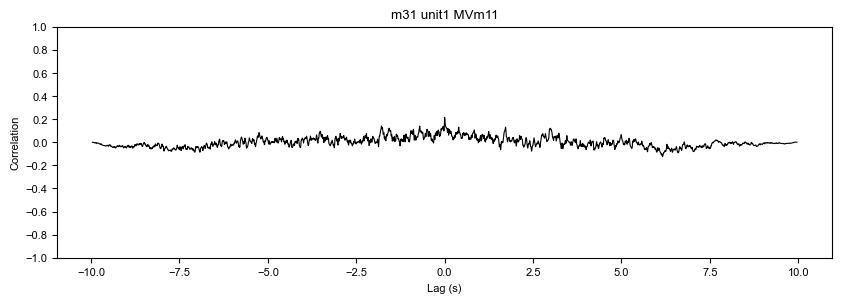

m31 unit1 MVm11: peak=0.215 at lag=0.0000s | at_zero=0.215


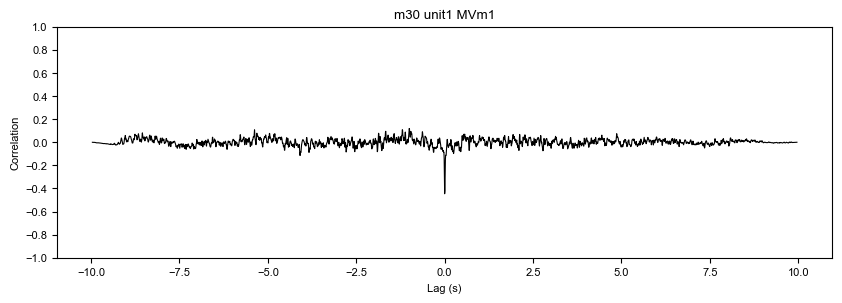

m30 unit1 MVm1: peak=-0.446 at lag=0.0000s | at_zero=-0.446


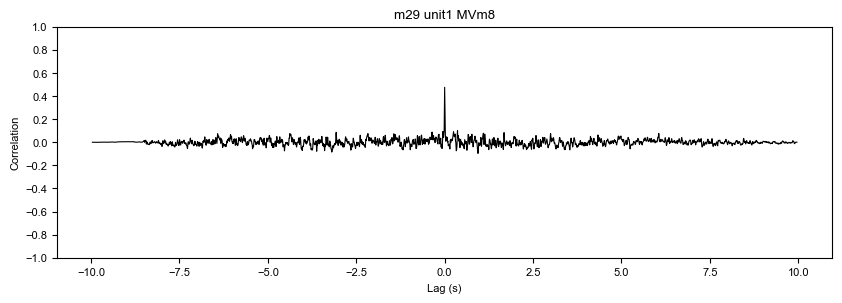

m29 unit1 MVm8: peak=0.476 at lag=0.0000s | at_zero=0.476


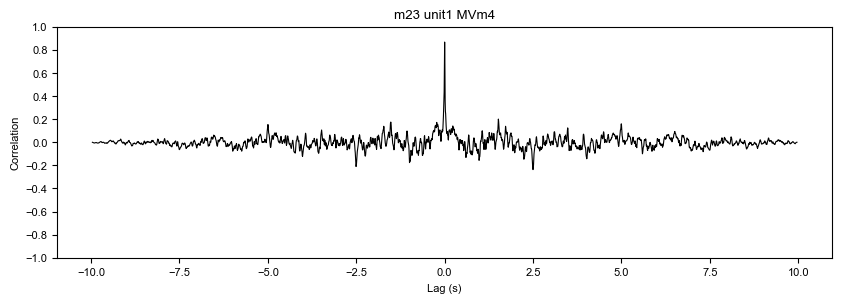

m23 unit1 MVm4: peak=0.867 at lag=0.0000s | at_zero=0.867


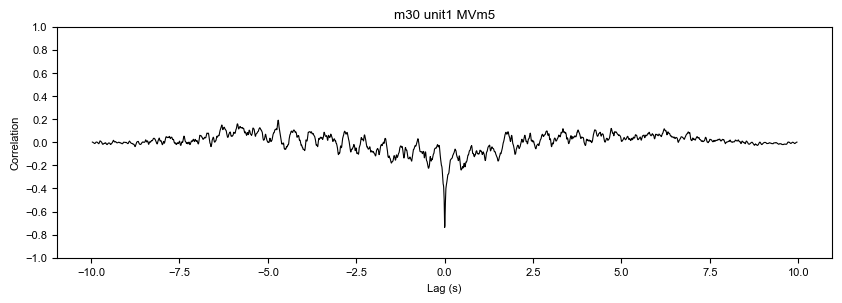

m30 unit1 MVm5: peak=-0.738 at lag=0.0000s | at_zero=-0.738


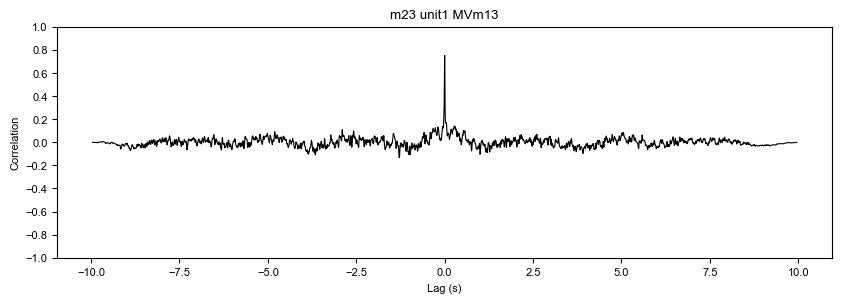

m23 unit1 MVm13: peak=0.750 at lag=0.0000s | at_zero=0.750


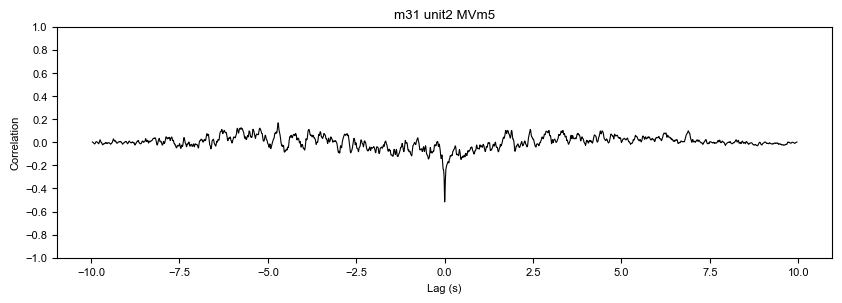

m31 unit2 MVm5: peak=-0.517 at lag=0.0000s | at_zero=-0.517


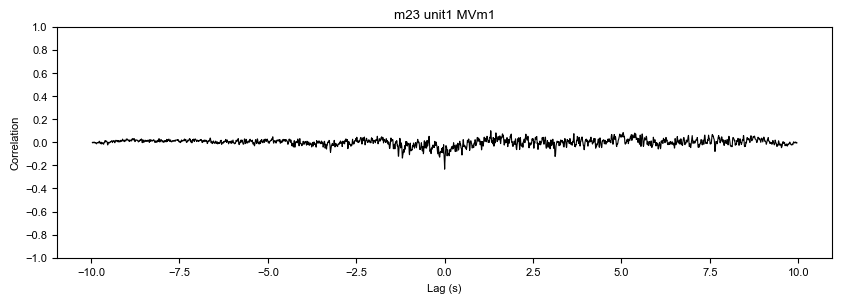

m23 unit1 MVm1: peak=-0.233 at lag=0.0000s | at_zero=-0.233


In [6]:
for filepath in prediction_files:
    with open(filepath, 'rb') as f:
        savedData = pickle.load(f)
    moth     = os.path.basename(filepath).split('_')[0]
    unitID   = os.path.basename(filepath).split('_')[1]
    vid_moth = os.path.basename(filepath).split('_')[3]
    
    df_proj   = savedData[2]
    upsampled = savedData[3]
    chunk_size = 210
    upsampled_ds = upsampled[:len(upsampled)//chunk_size * chunk_size].reshape(-1, chunk_size).mean(axis=1)
    p_spike = df_proj['pred_max'].values[::chunk_size]
    min_len = min(len(p_spike), len(upsampled_ds))
    p_spike = p_spike[:min_len]
    upsampled_ds = upsampled_ds[:min_len]
    
    predcorr = np.correlate(p_spike - np.mean(p_spike),
                        upsampled_ds - np.mean(upsampled_ds), mode='full')
    predcorr_normalised = predcorr / (len(p_spike) * np.std(p_spike) * np.std(upsampled_ds))
    lags = np.arange(-(len(p_spike)-1), len(p_spike)) / (Fs/chunk_size)
    peak_idx = np.argmax(np.abs(predcorr_normalised))
    zero_idx = np.argmin(np.abs(lags))
    
    plt.figure(figsize=(10, 3))
    plt.plot(lags, predcorr_normalised, 'k', linewidth=0.8)
    plt.ylim(-1, 1)
    plt.yticks(np.arange(-1, 1.2, 0.2))
    plt.xlabel('Lag (s)')
    plt.ylabel('Correlation')
    plt.title(f'{moth} {unitID} {vid_moth}')
    plt.savefig(out_fig + moth + '_' + unitID + '_' + vid_moth + '_crosscor.pdf')
    plt.show()
    plt.close()
    
    print(f'{moth} {unitID} {vid_moth}: peak={predcorr_normalised[peak_idx]:.3f} at lag={lags[peak_idx]:.4f}s | at_zero={predcorr_normalised[zero_idx]:.3f}')
    
    crosscor_results[f'{moth}_{unitID}_{vid_moth}'] = {
        'crosscor_at_zero':    predcorr_normalised[zero_idx],
        'crosscor_peak':       predcorr_normalised[peak_idx],
        'crosscor_peak_lag_s': lags[peak_idx]}
    
    predcorr_df = pd.DataFrame({'lag_seconds': lags, 'predcorr_normalised': predcorr_normalised})
    predcorr_df.to_csv(out_path + moth + '_' + unitID + '_for_' + vid_moth + '_predcorrnorm.csv', index=False)

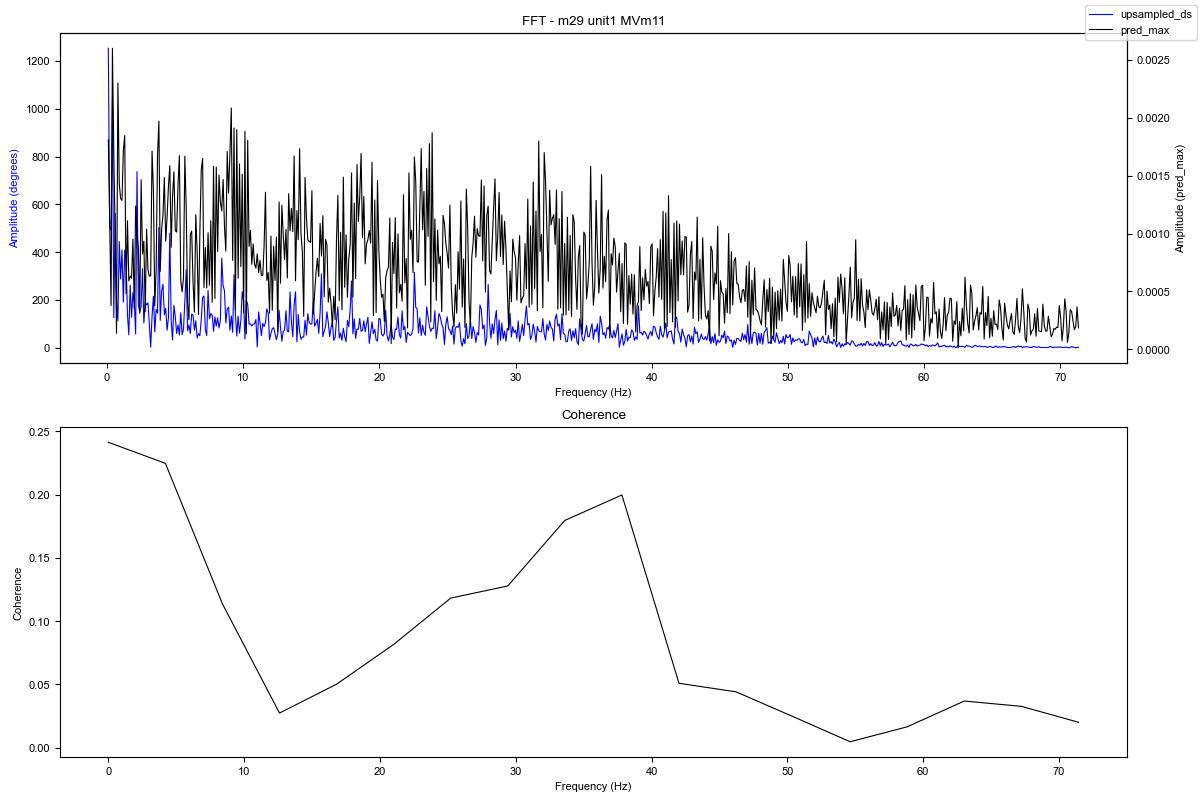

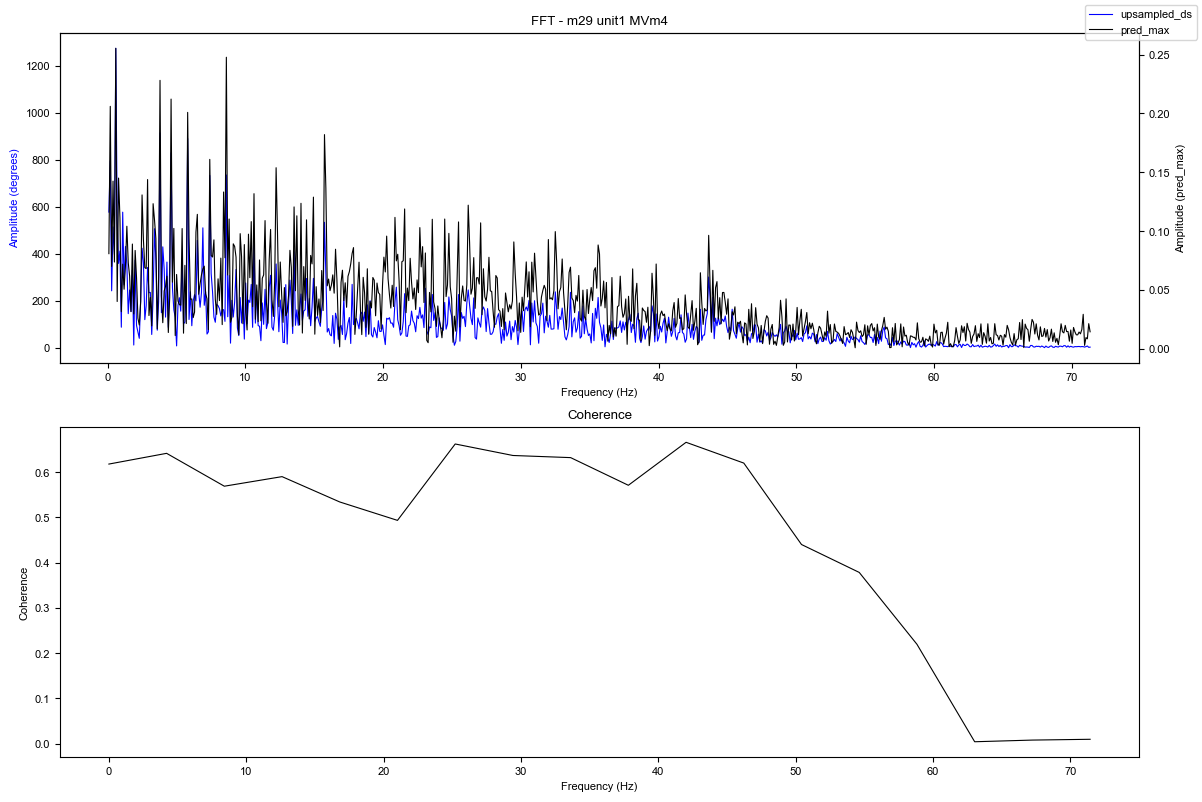

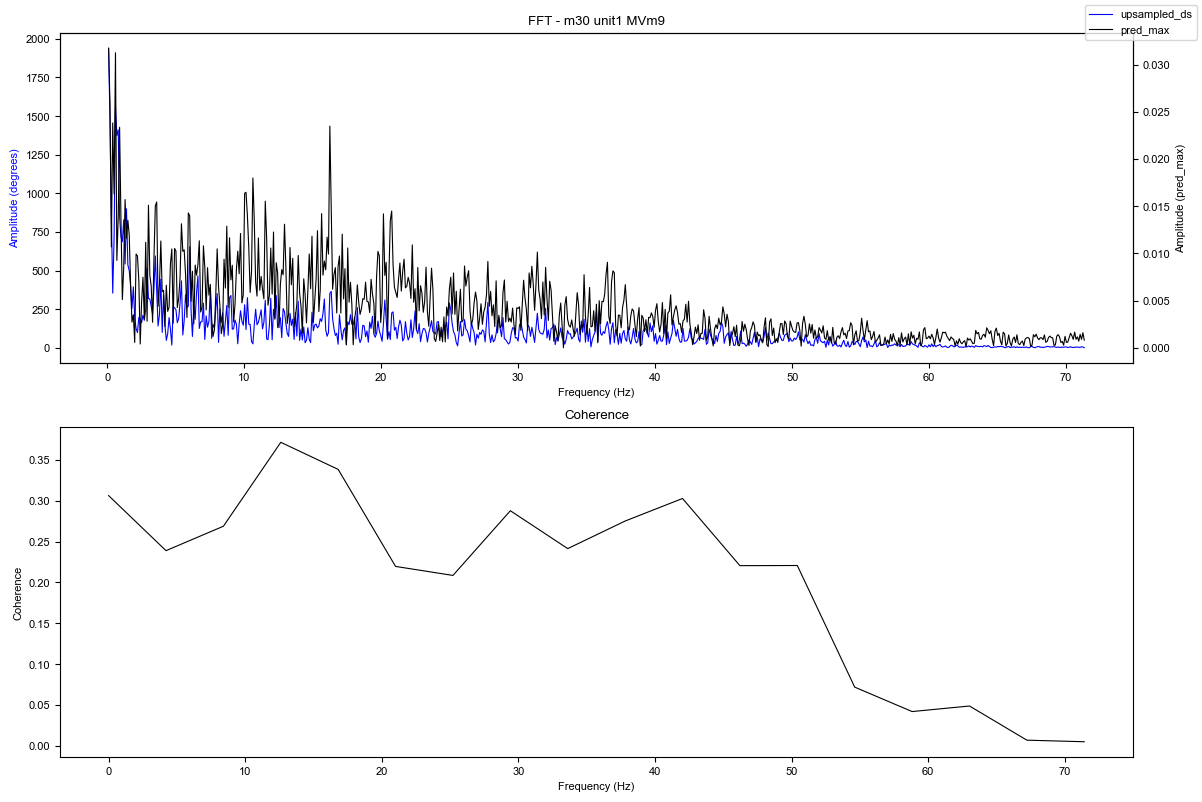

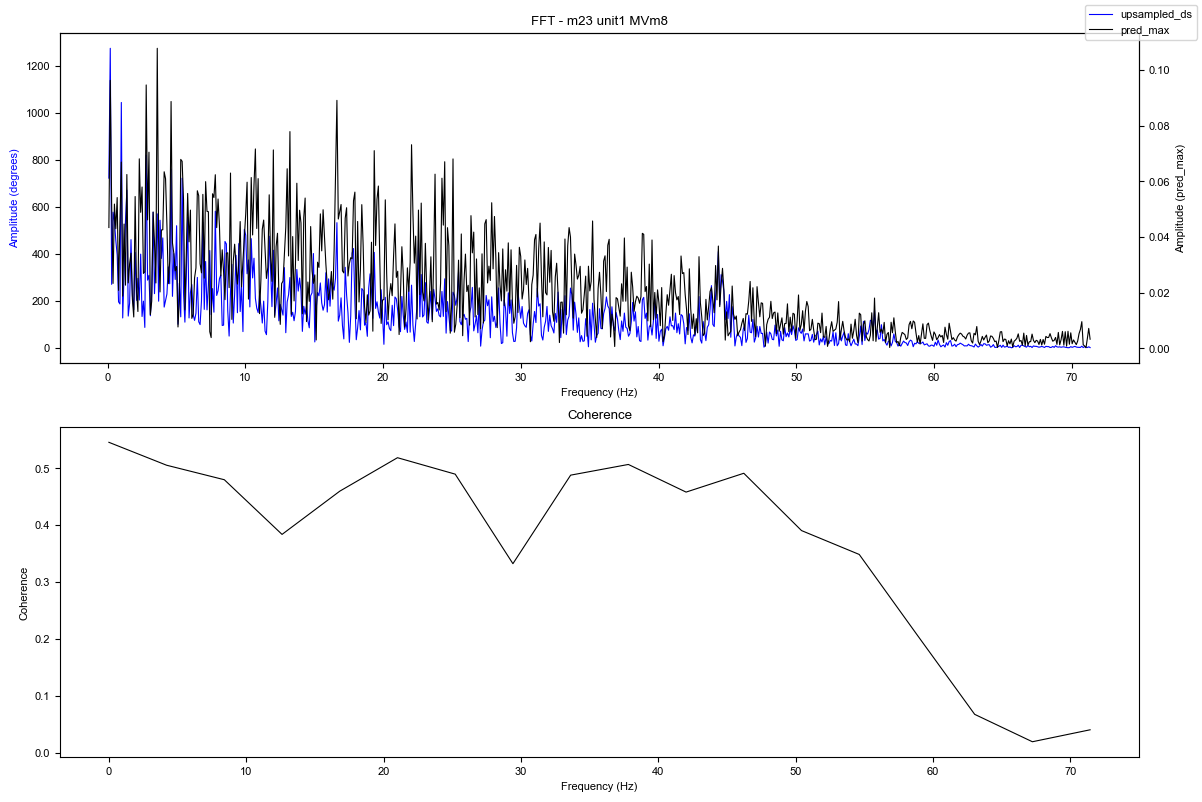

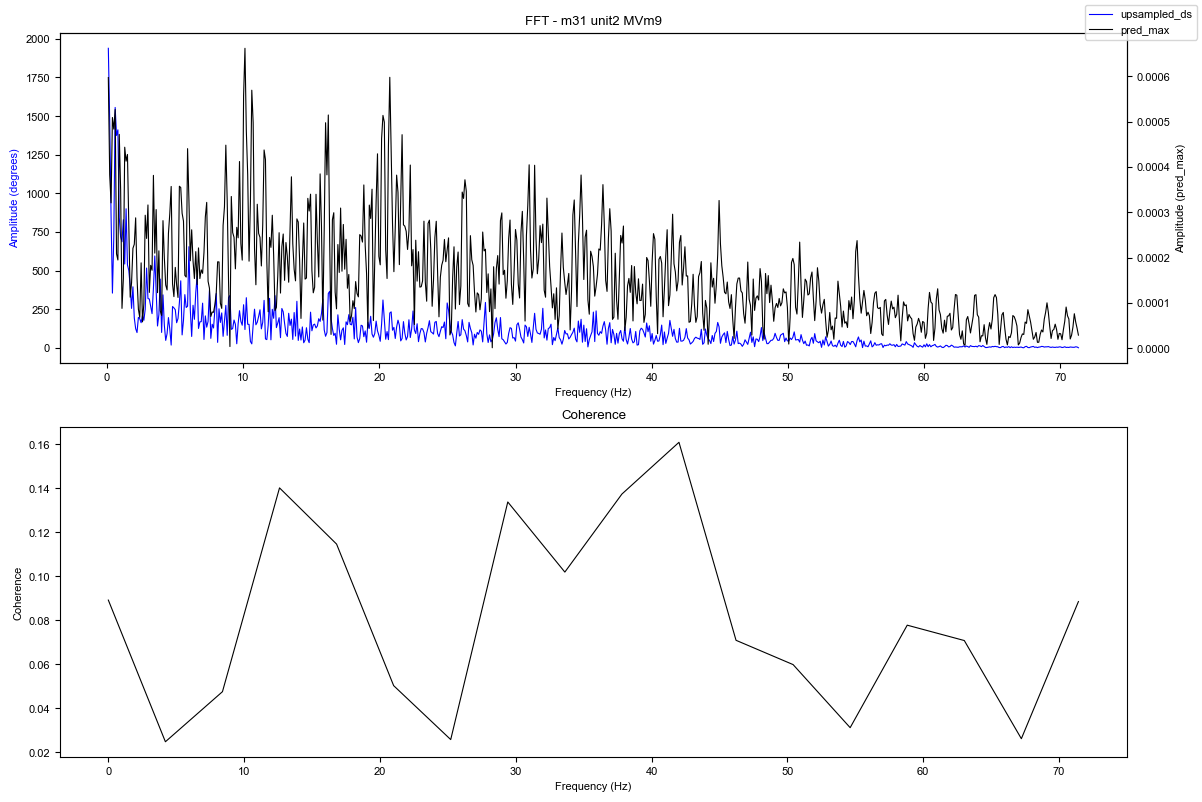

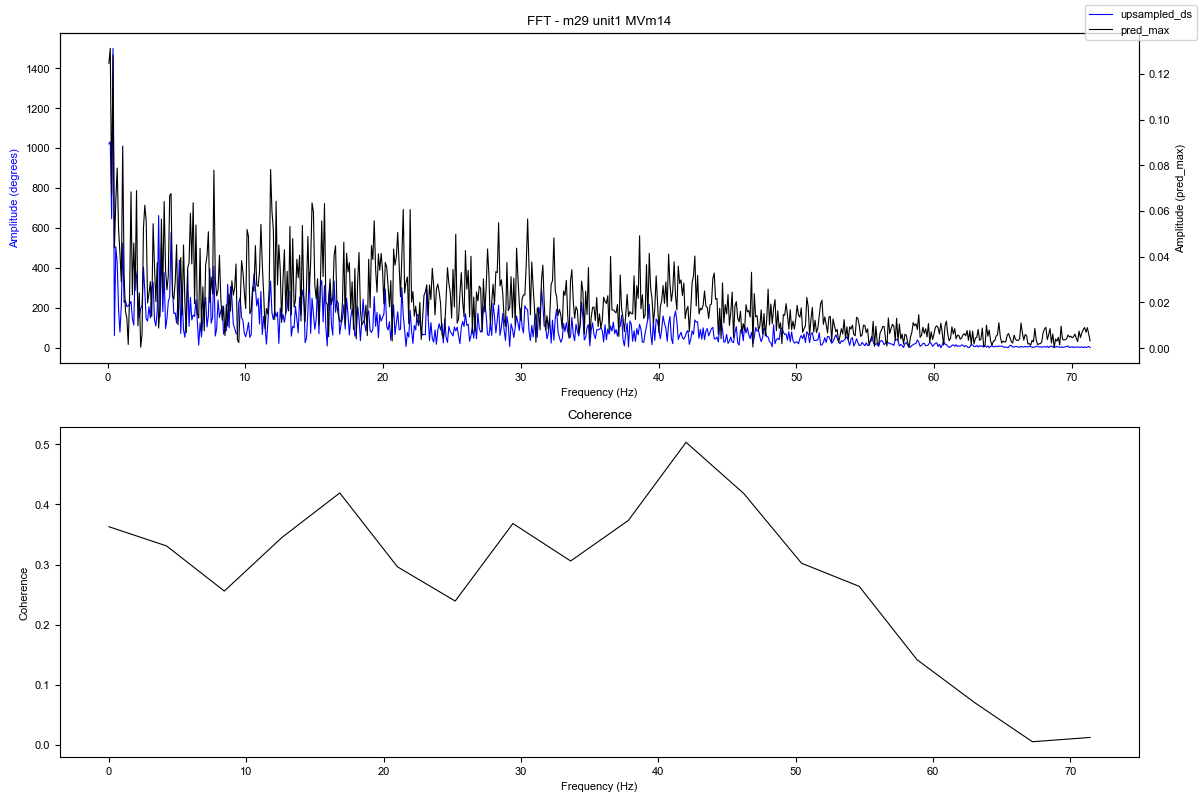

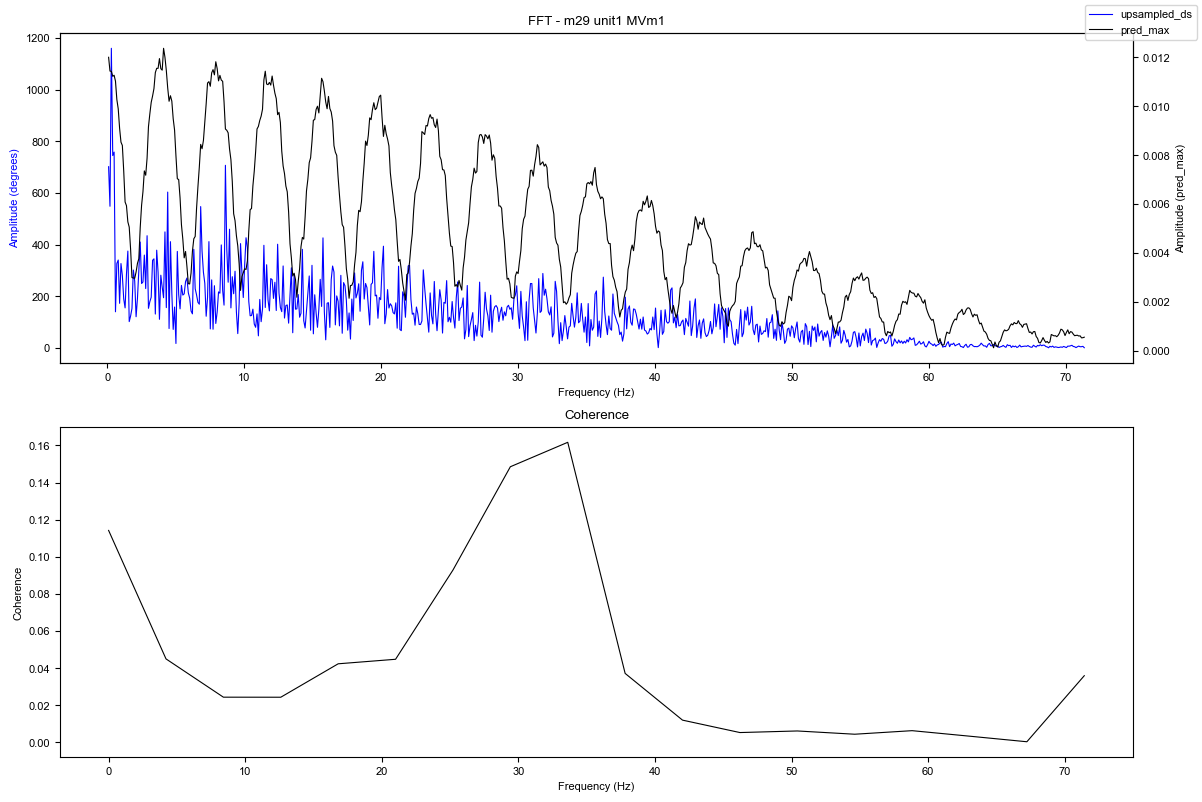

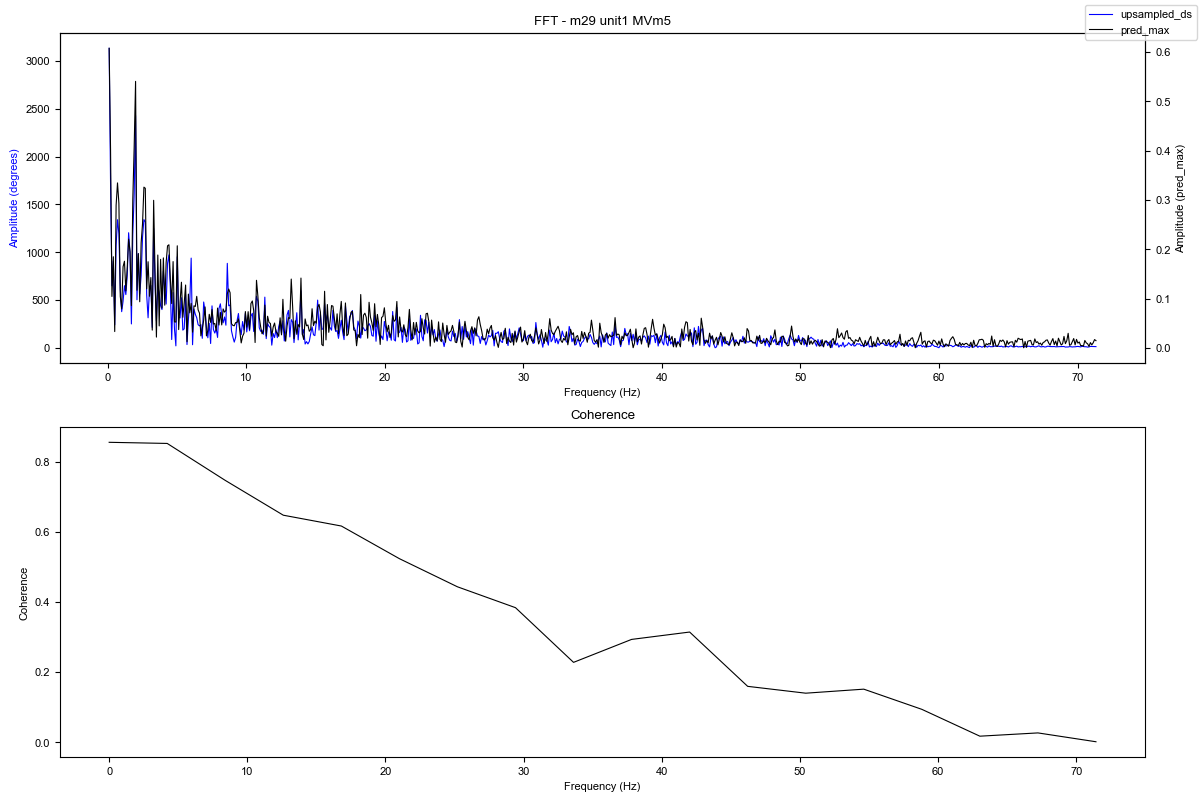

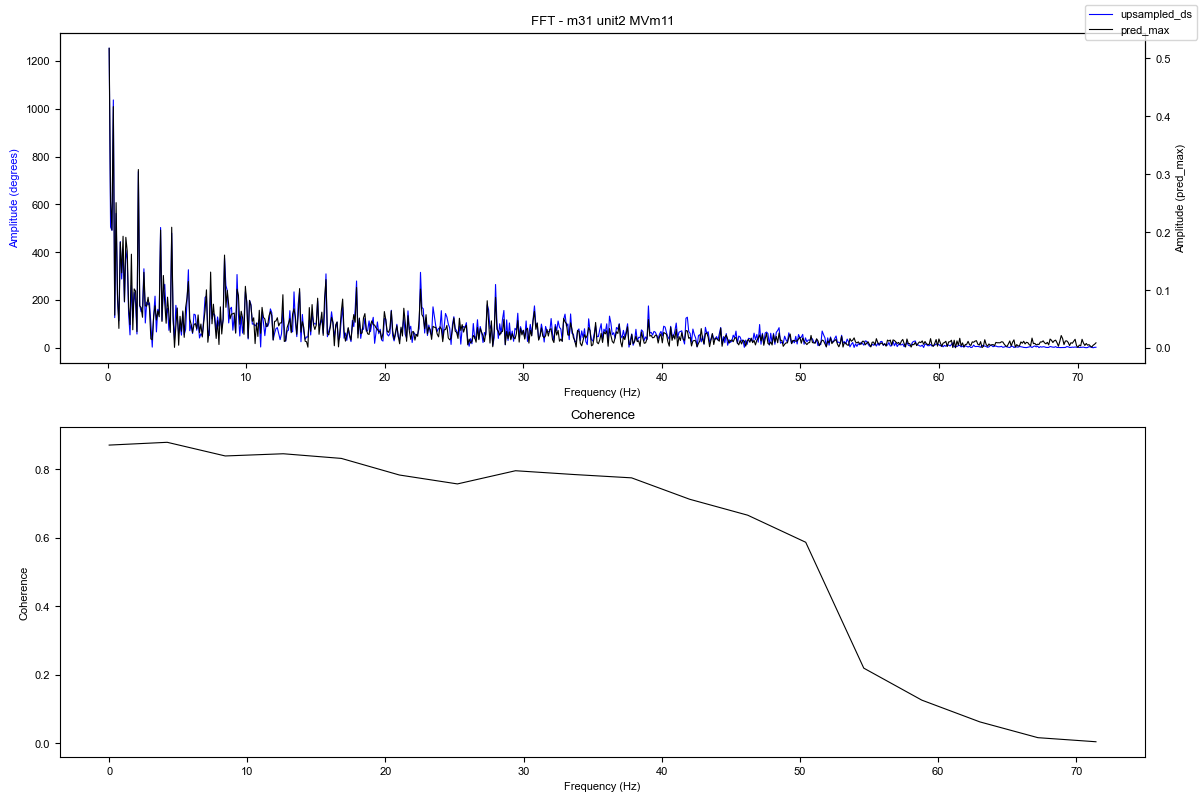

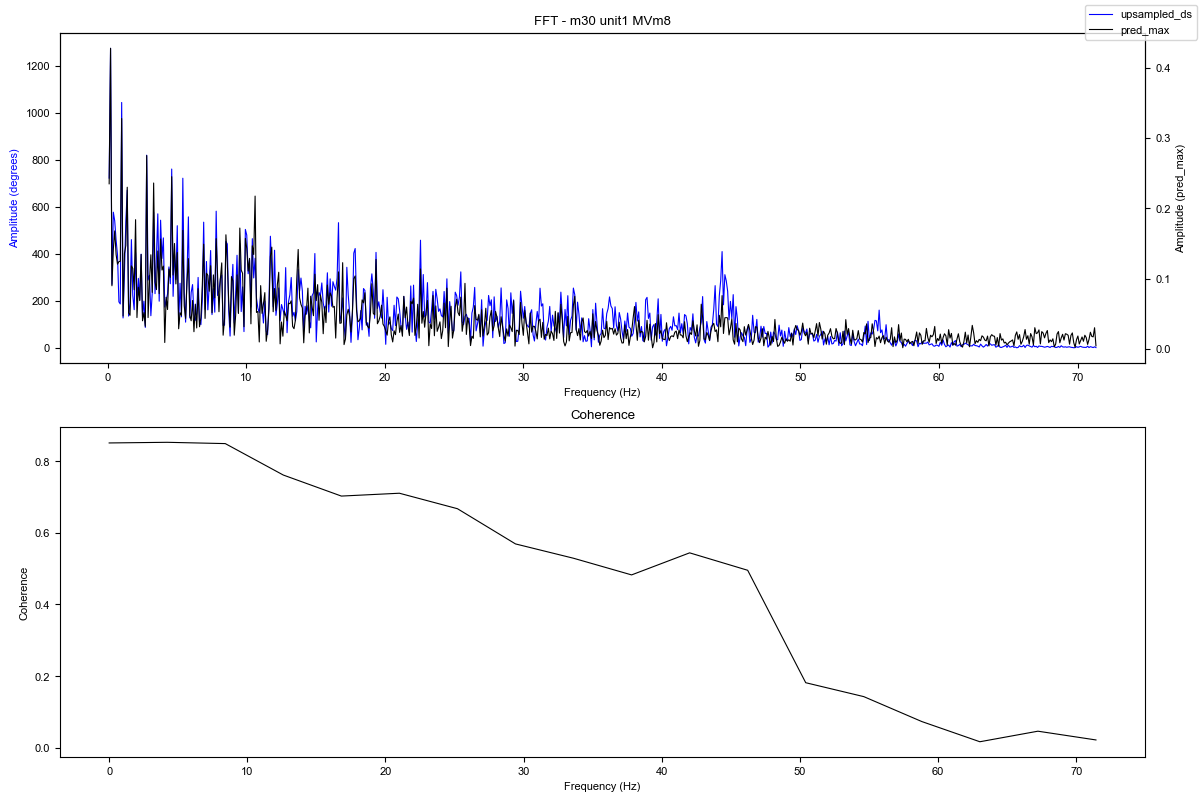

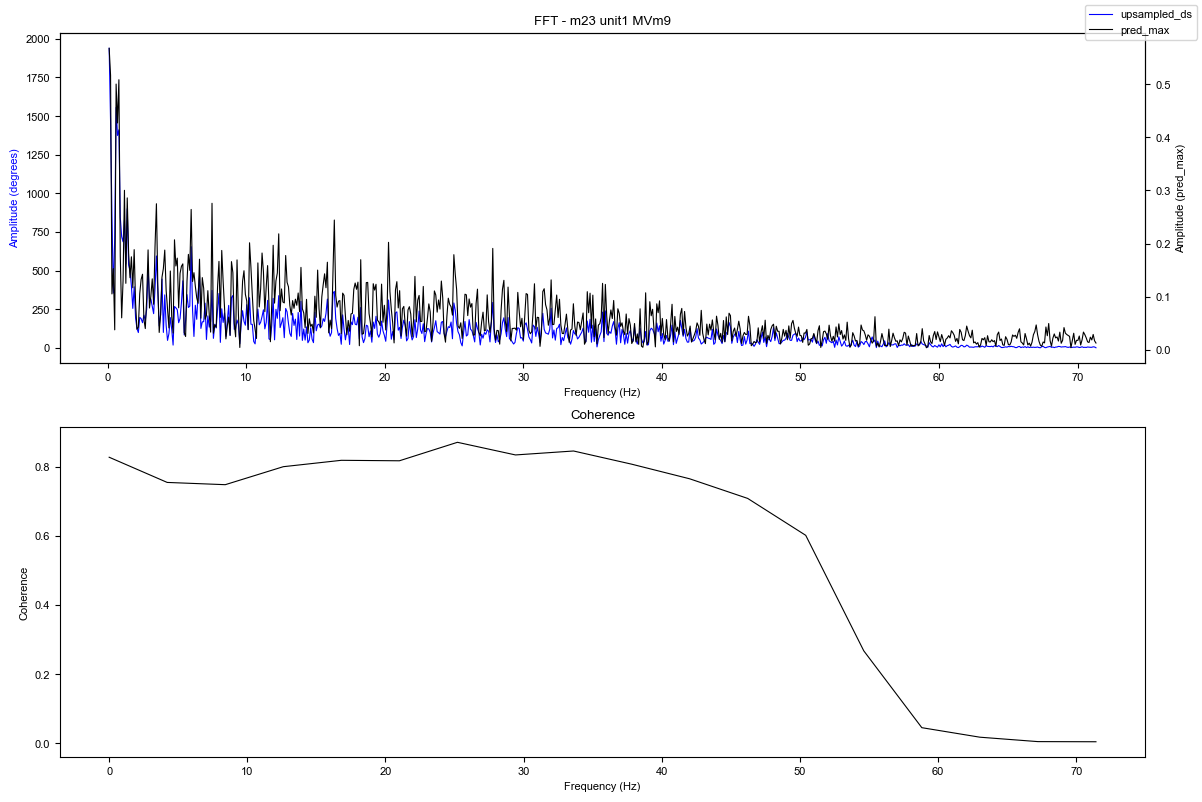

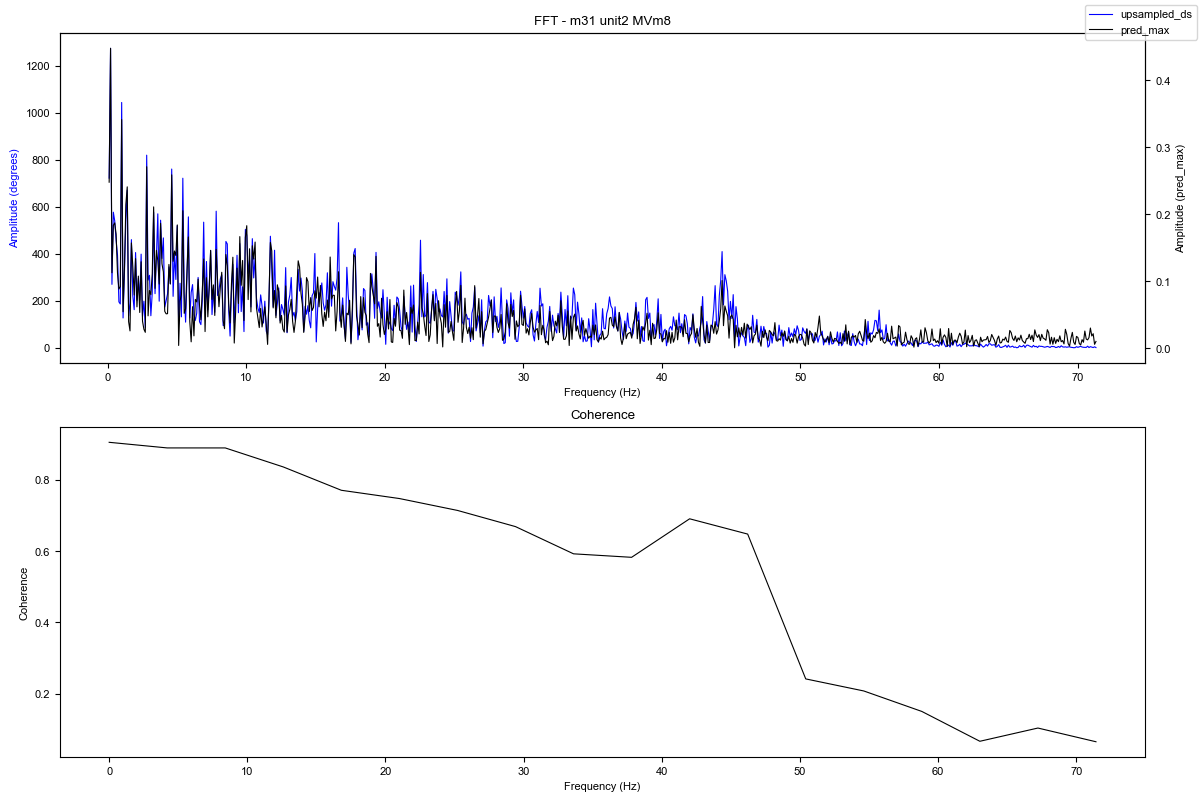

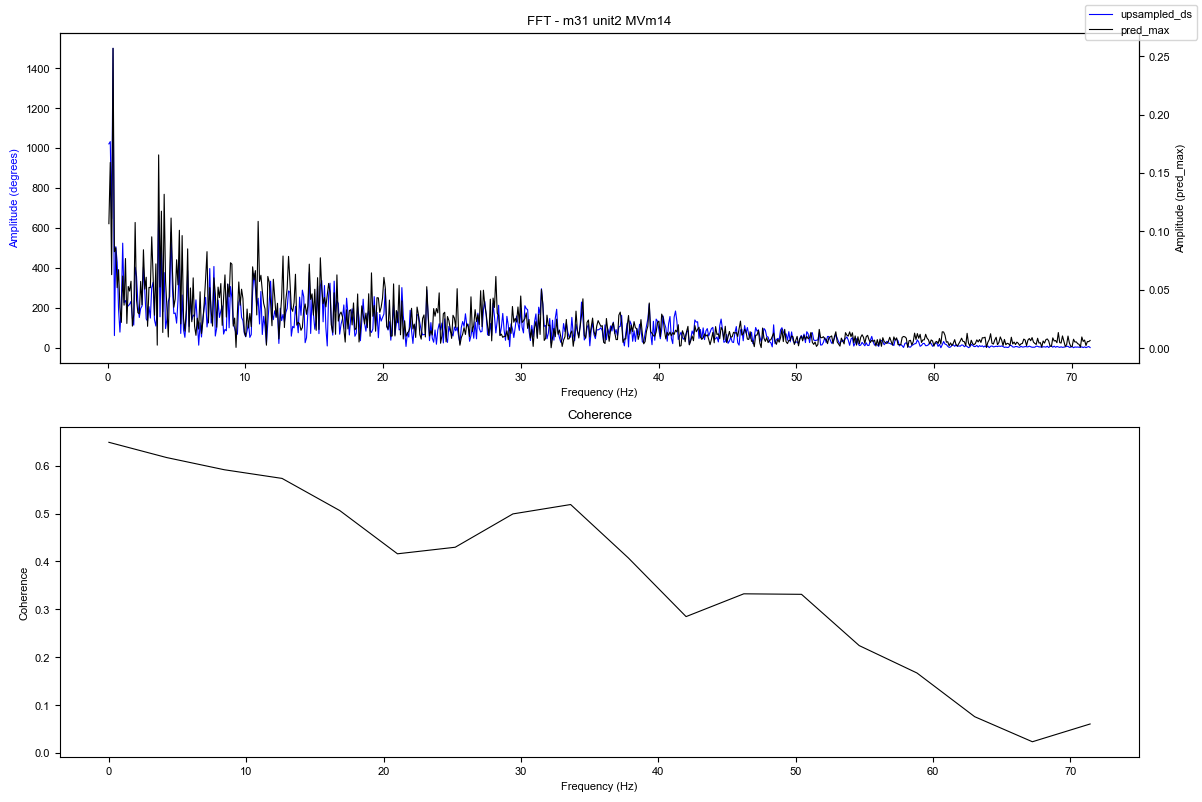

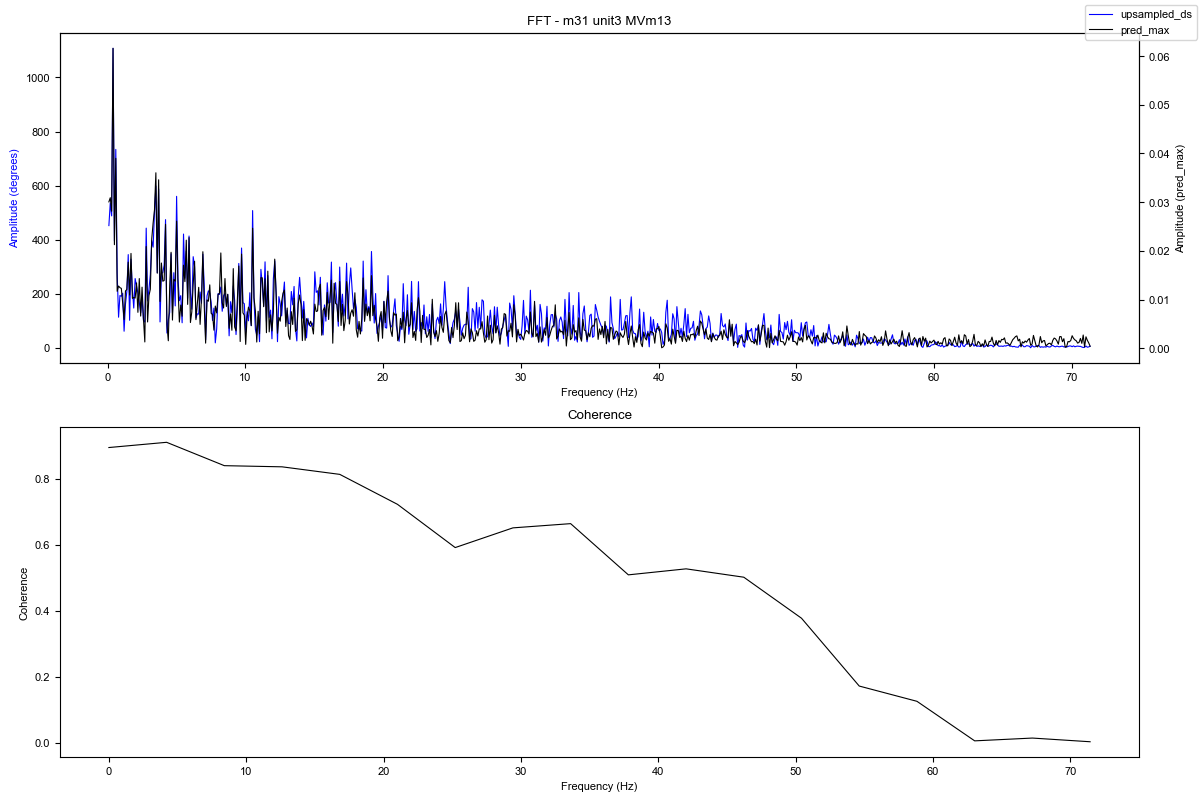

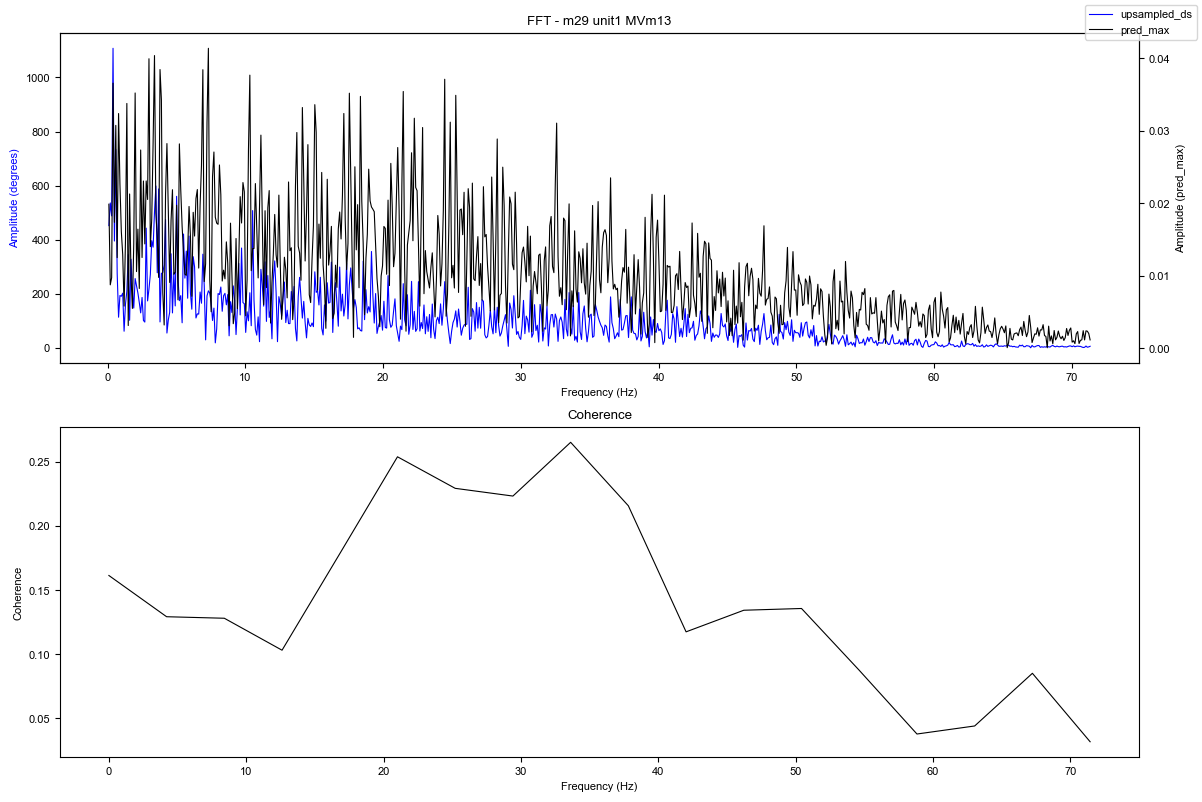

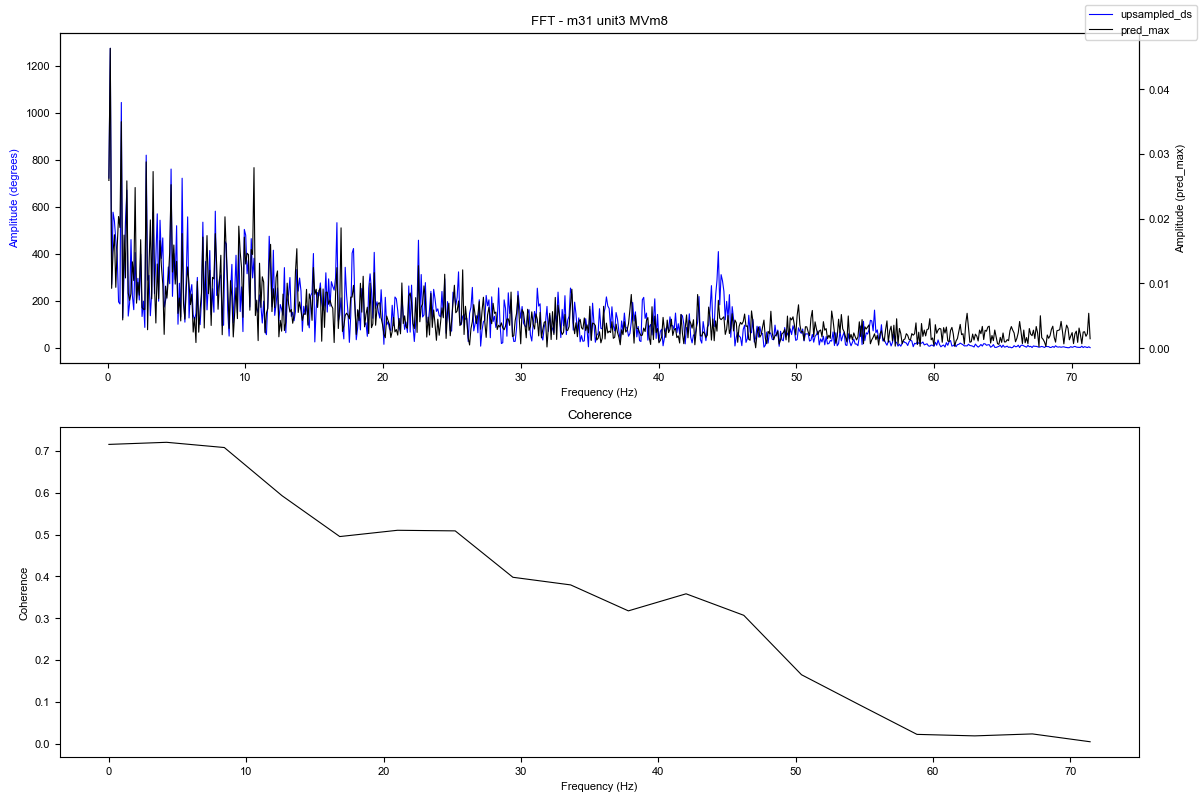

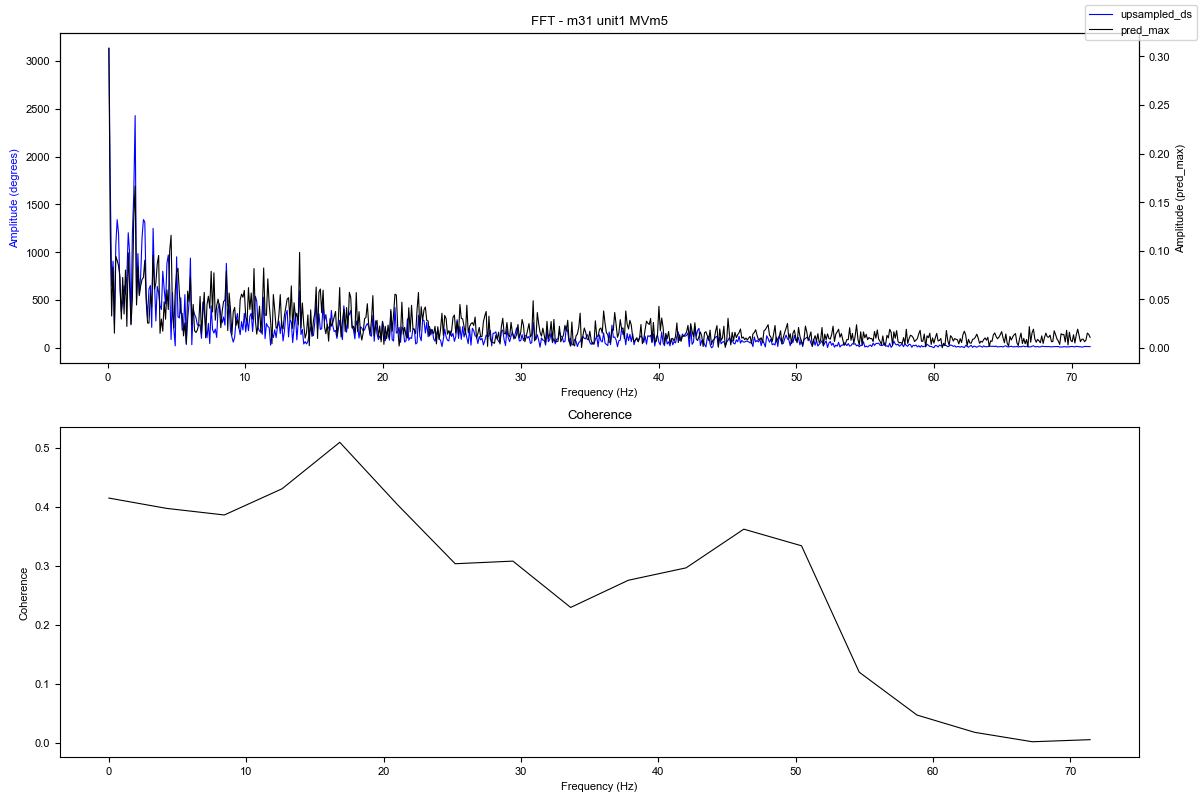

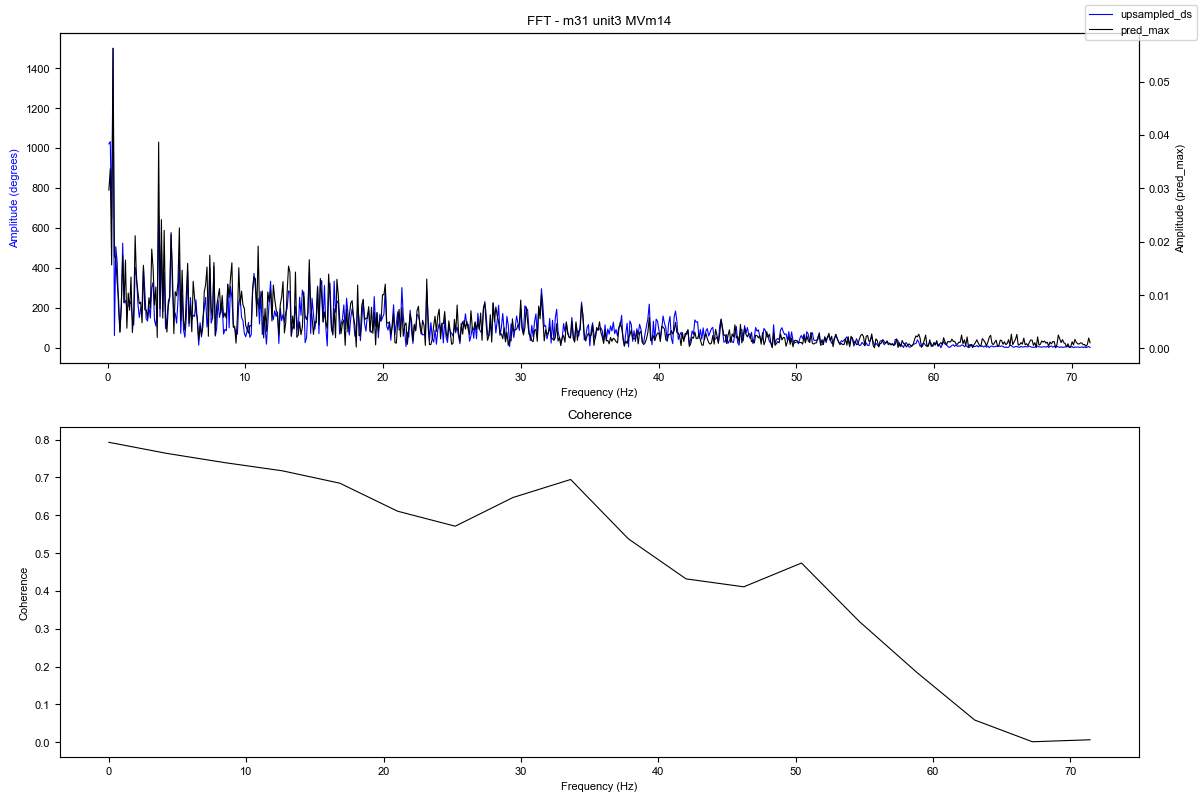

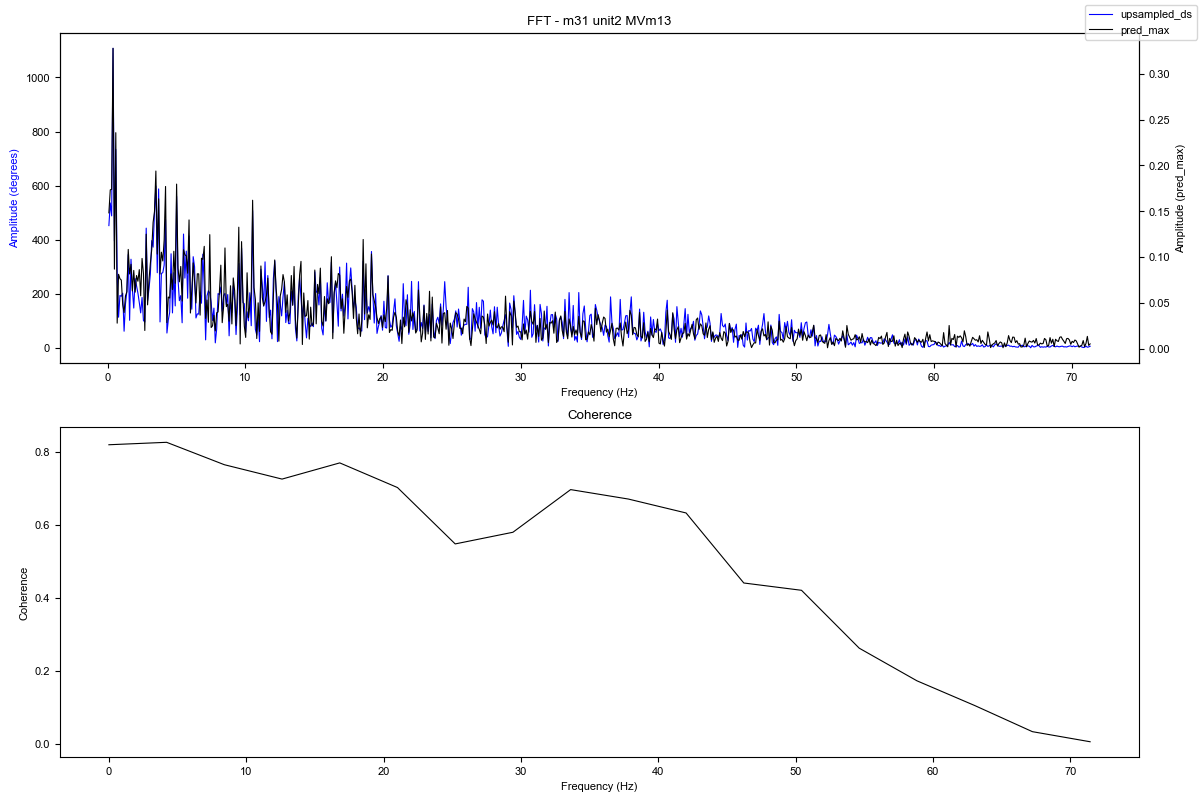

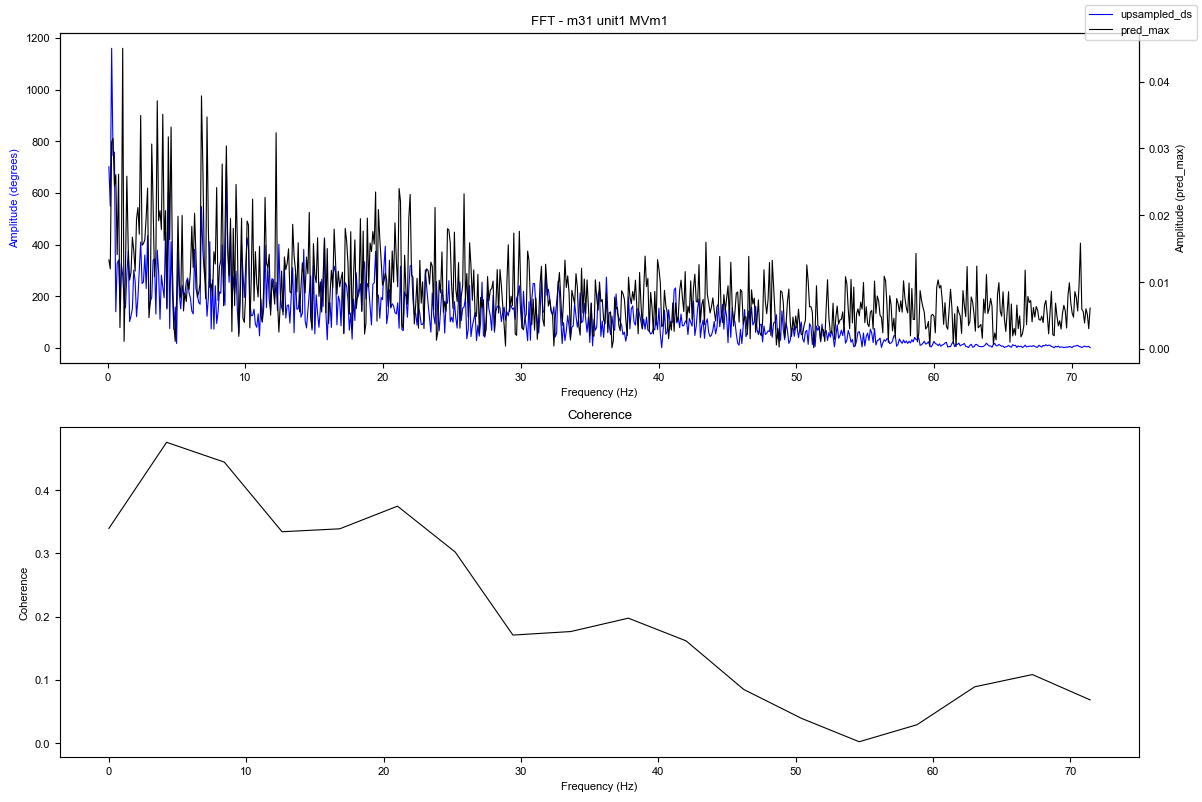

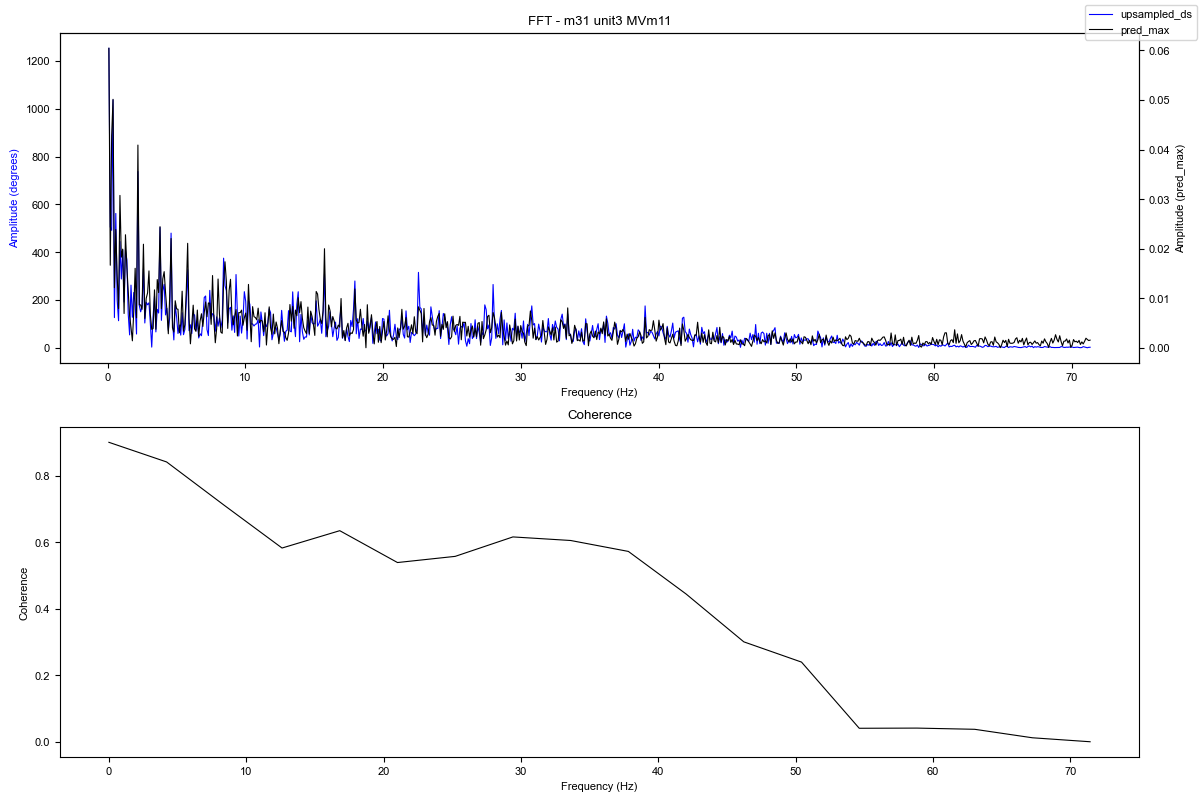

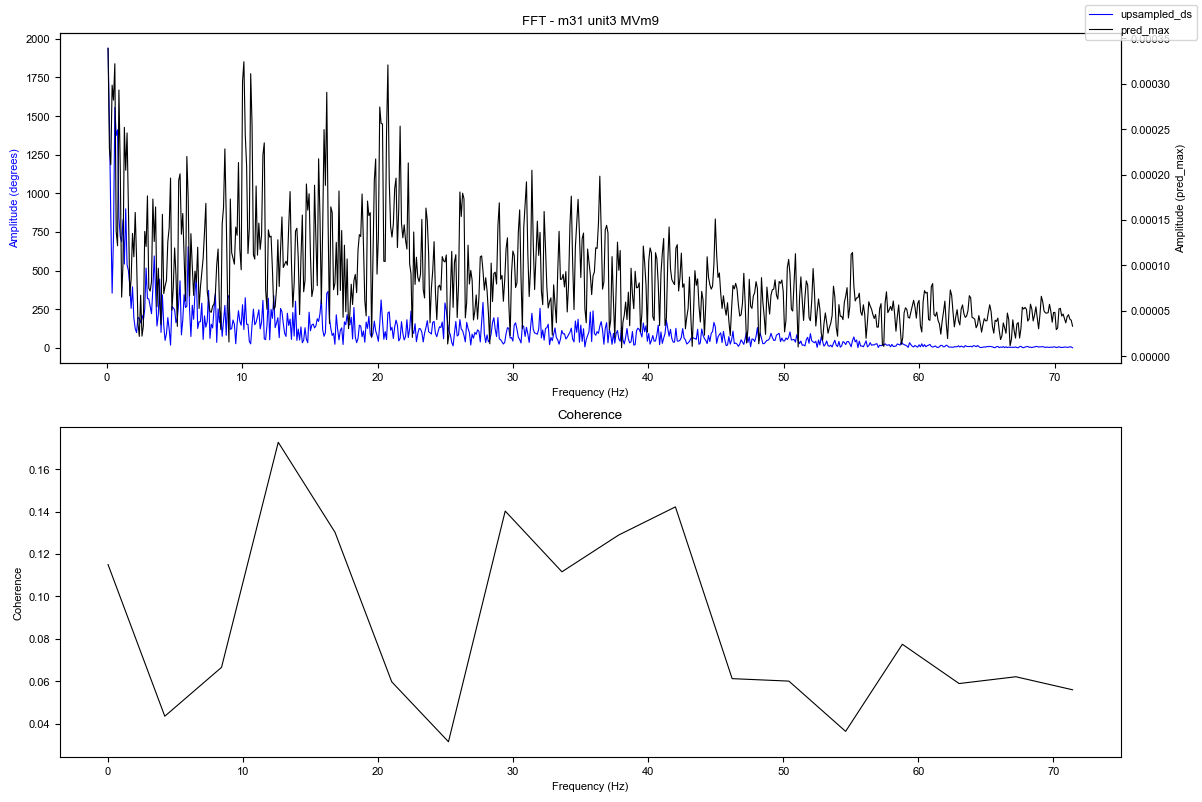

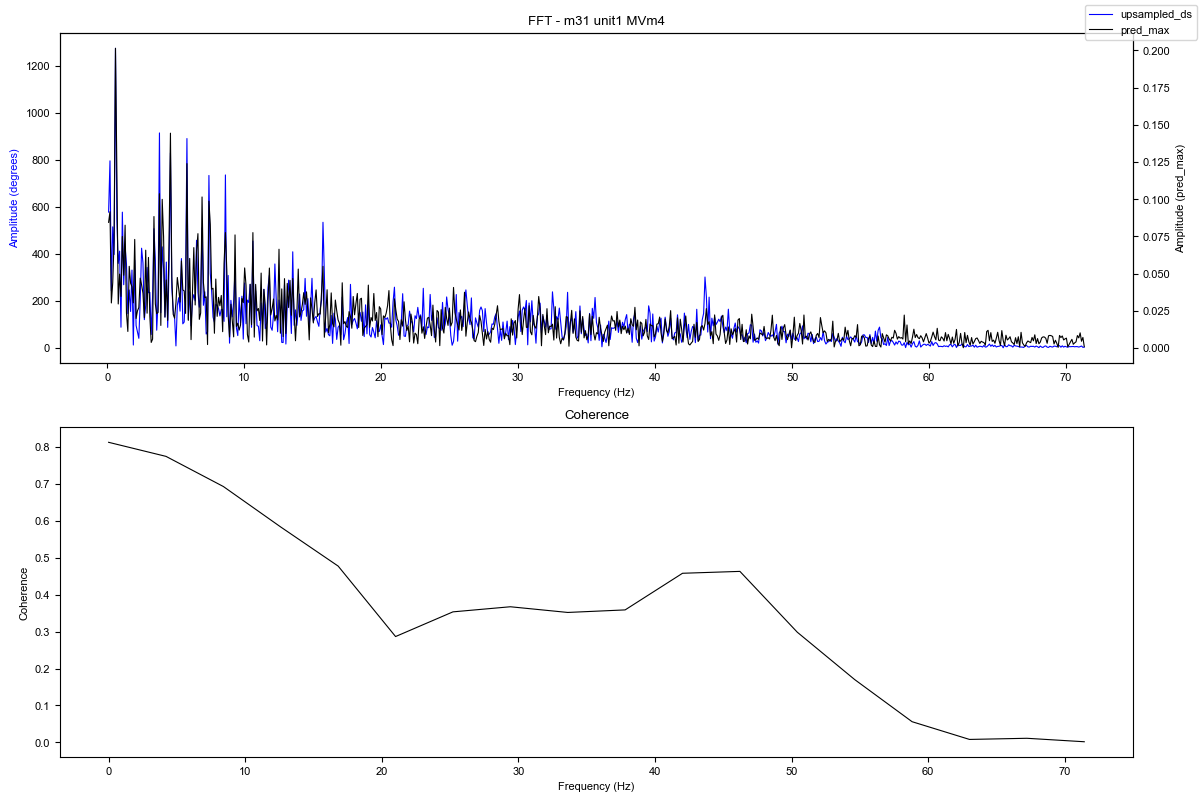

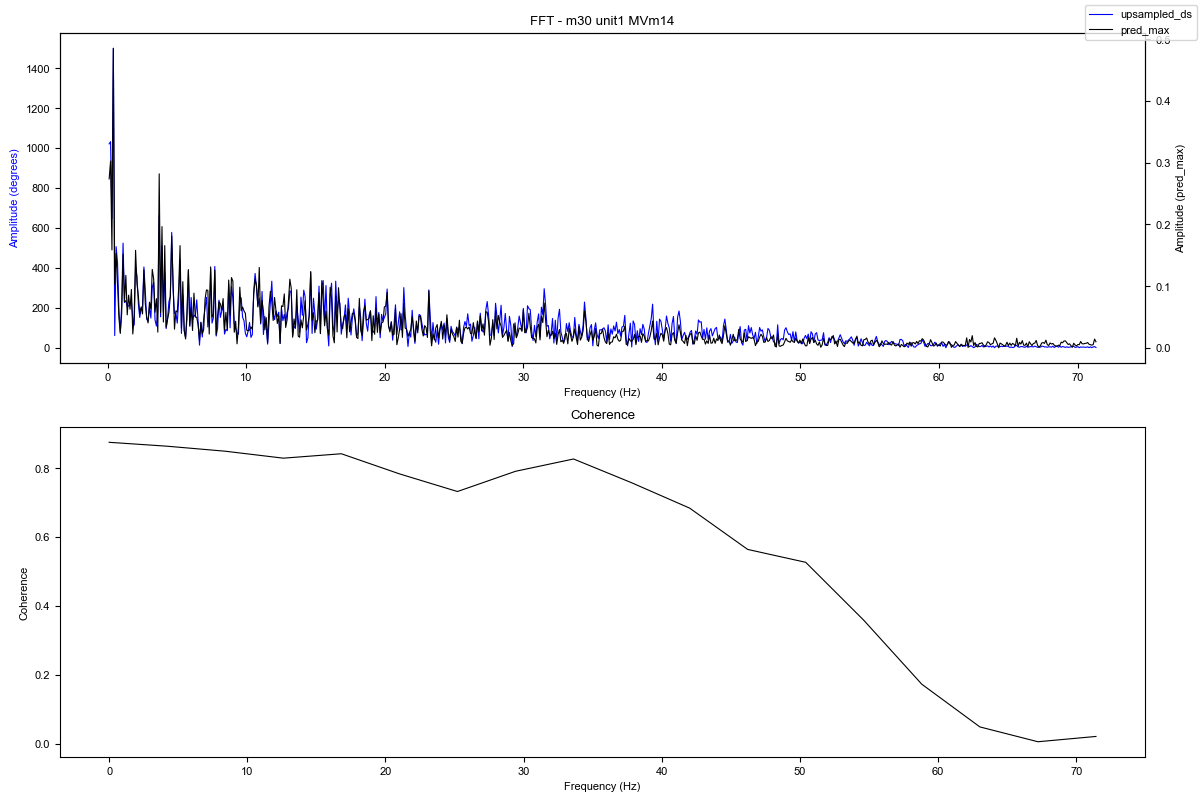

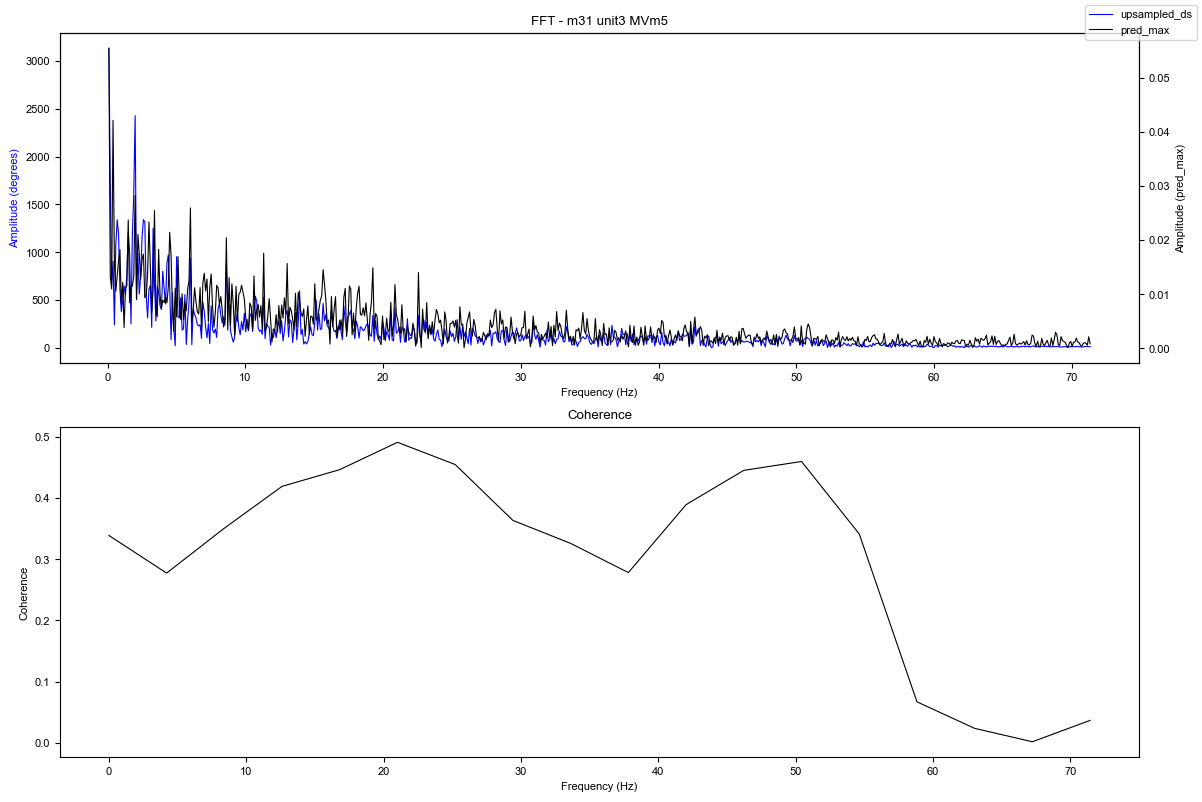

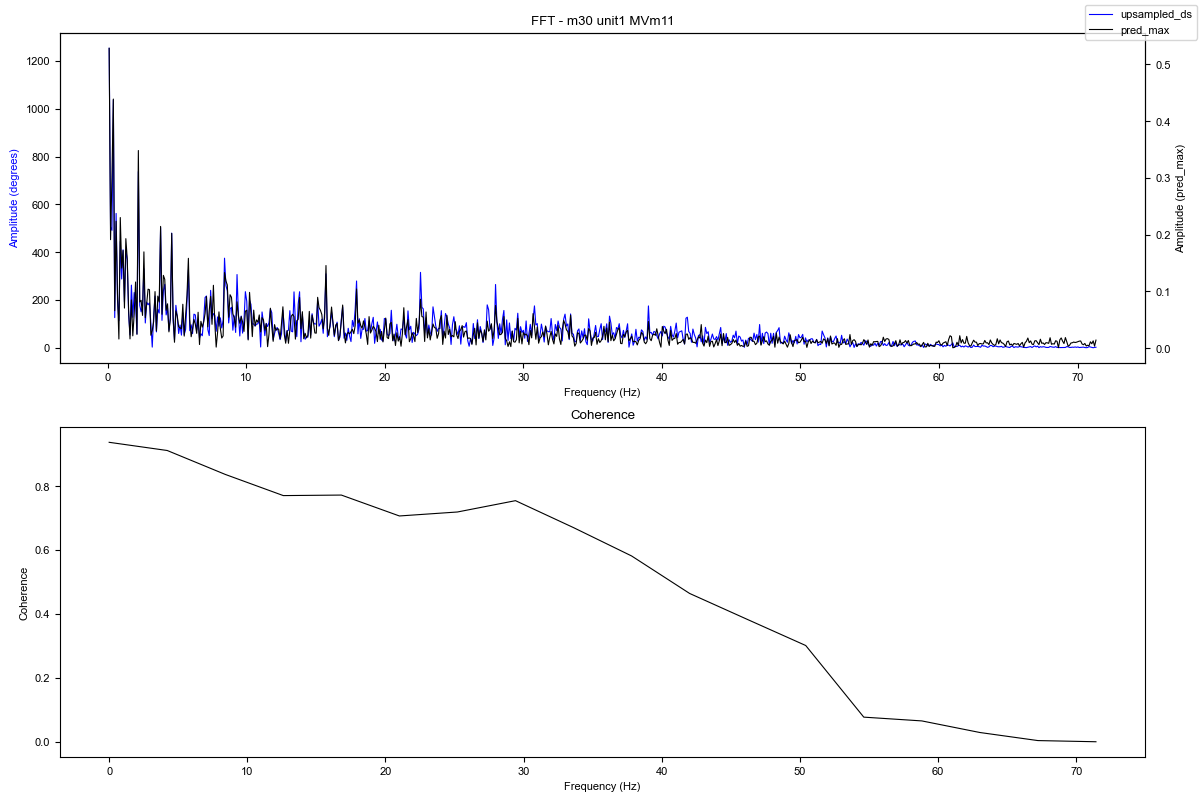

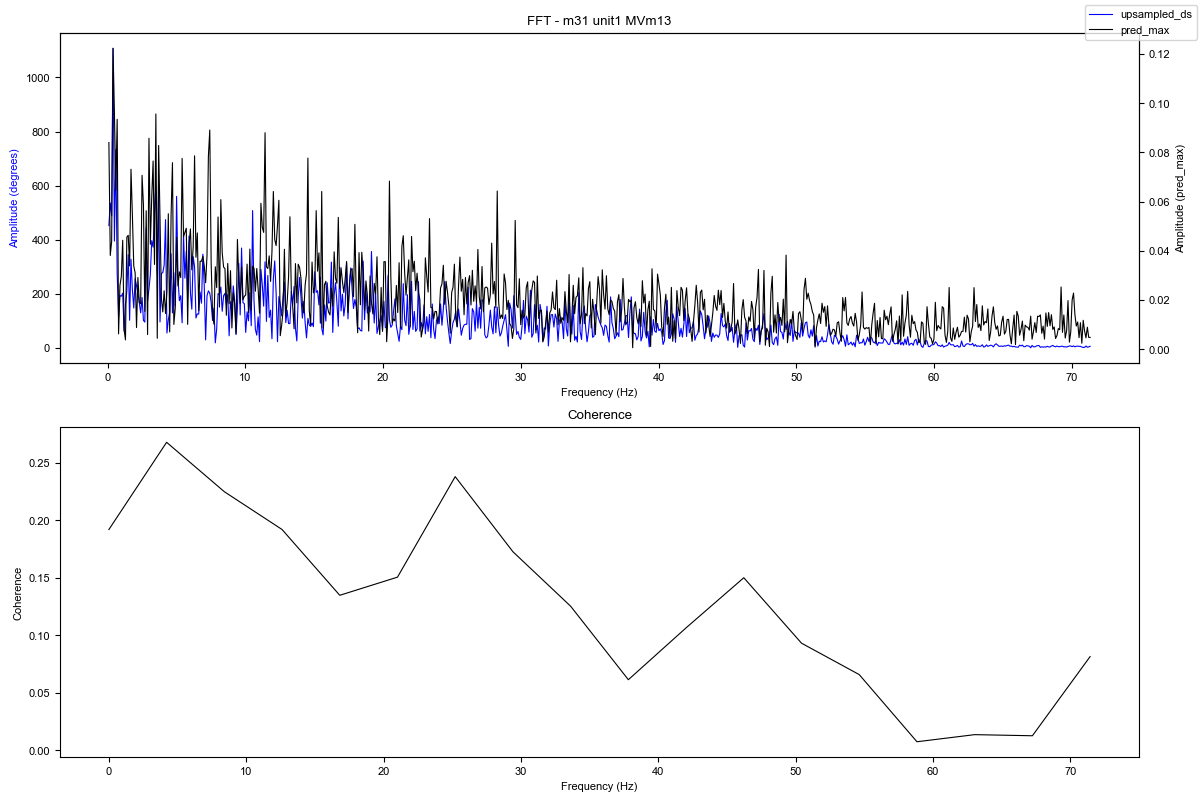

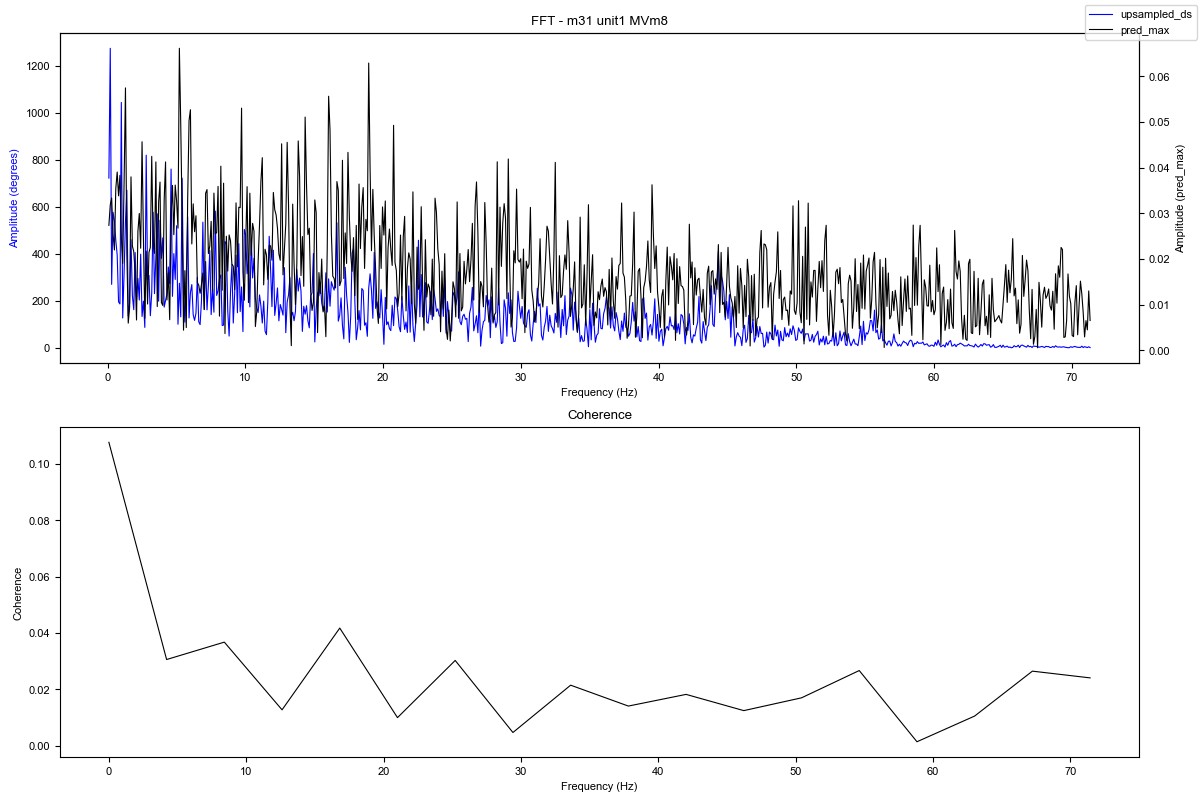

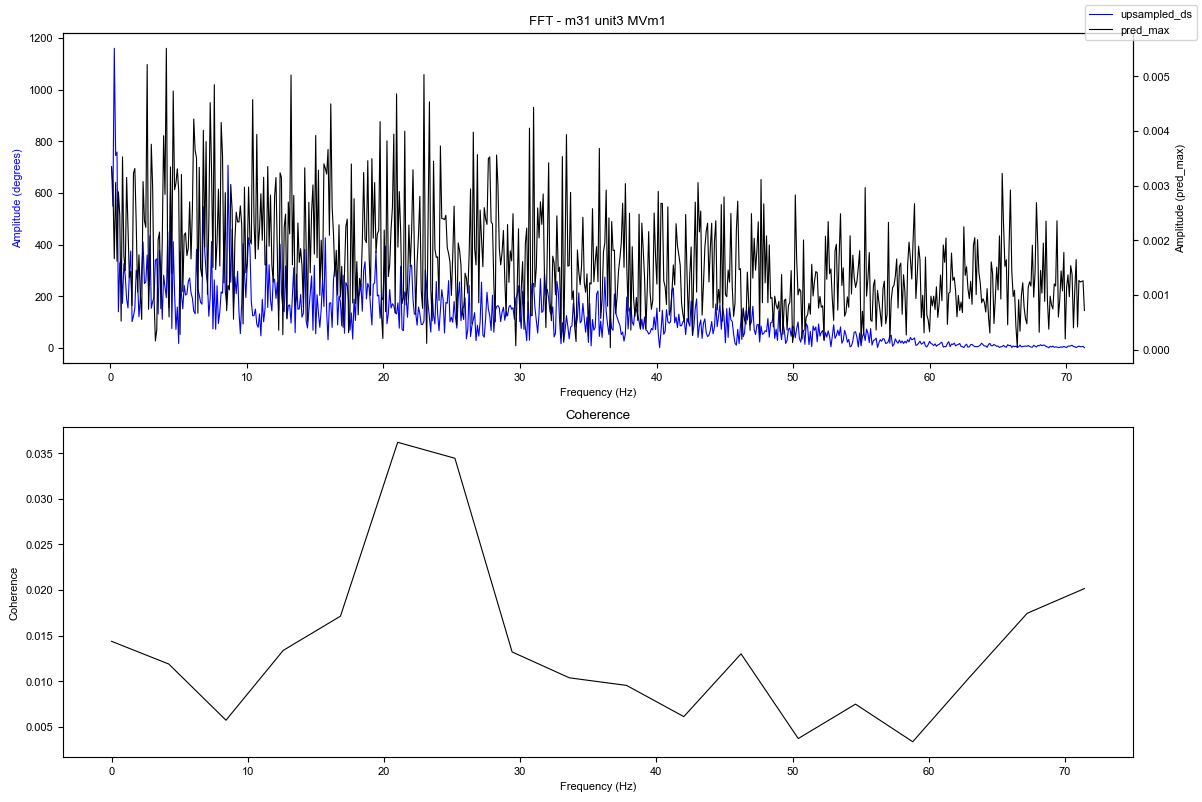

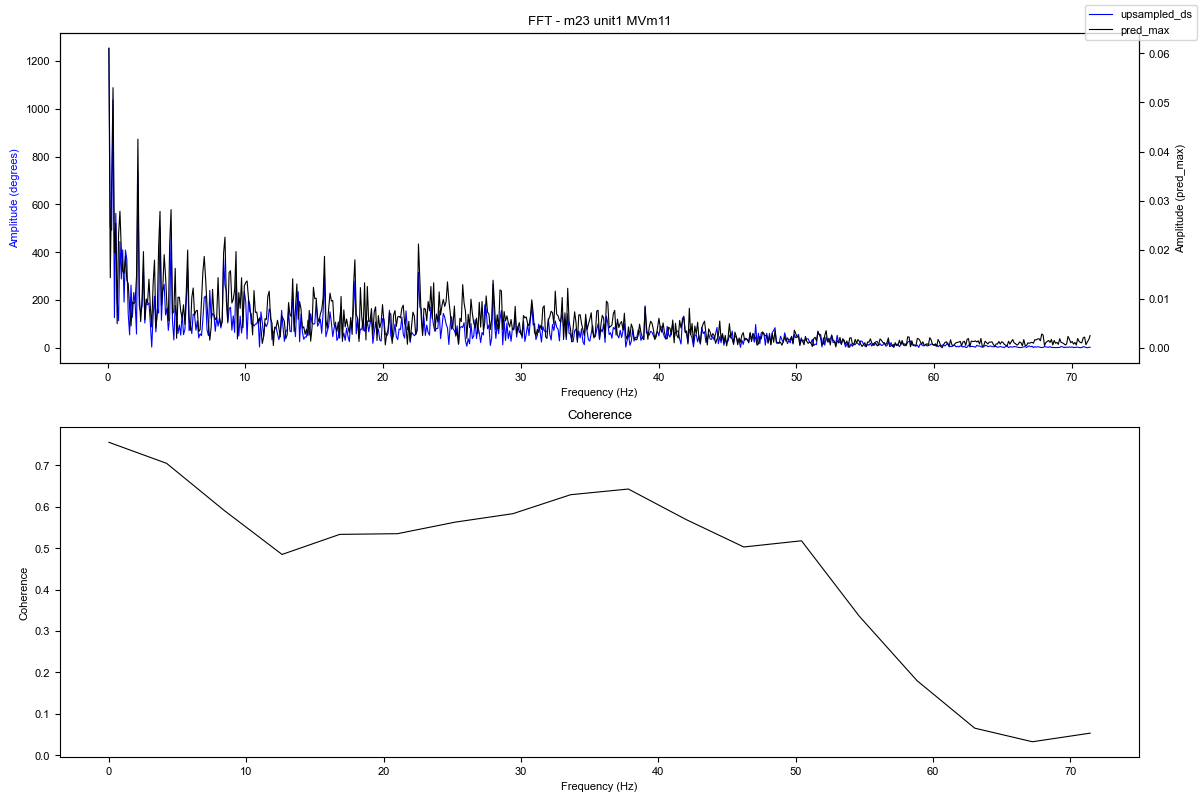

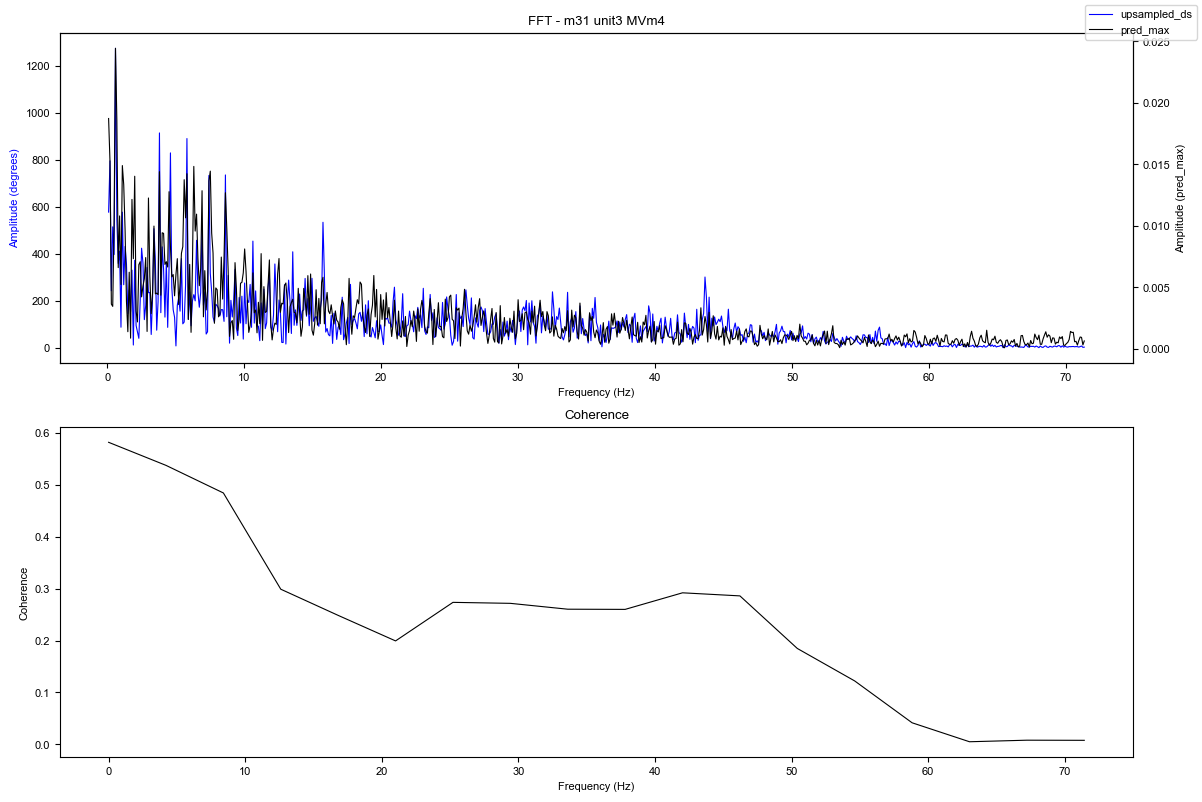

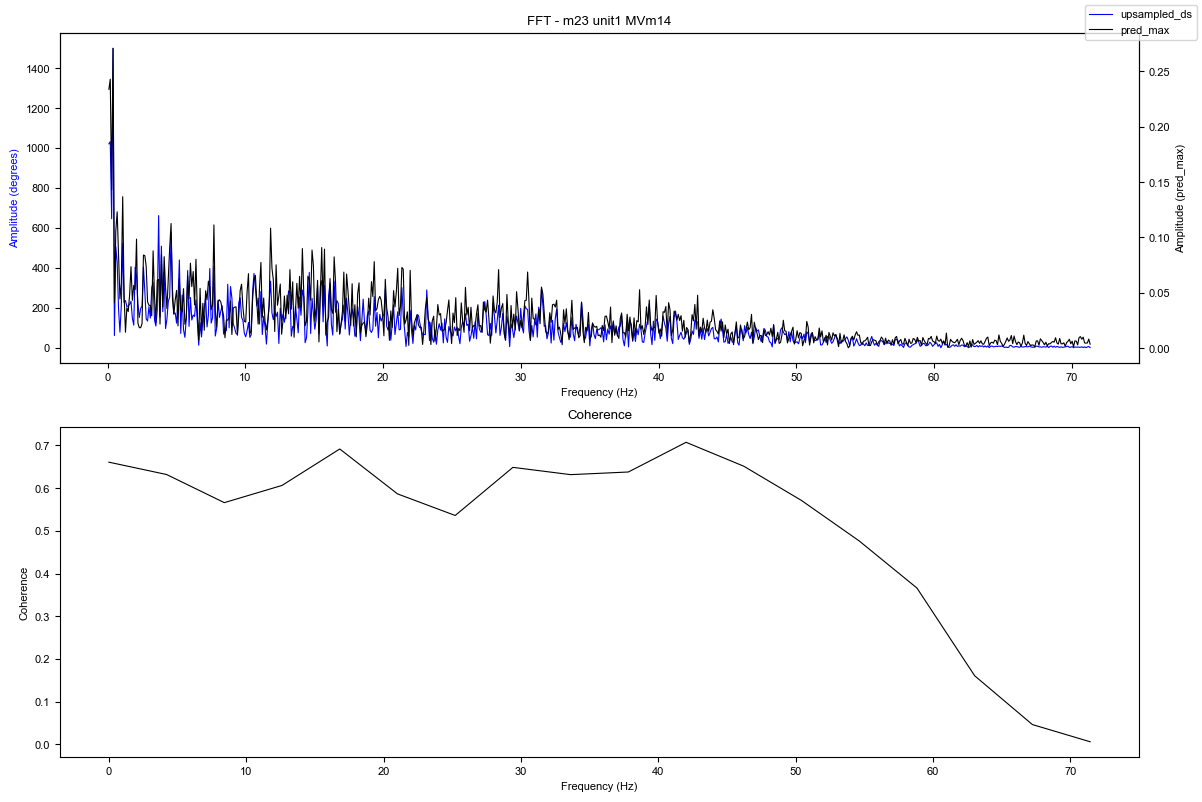

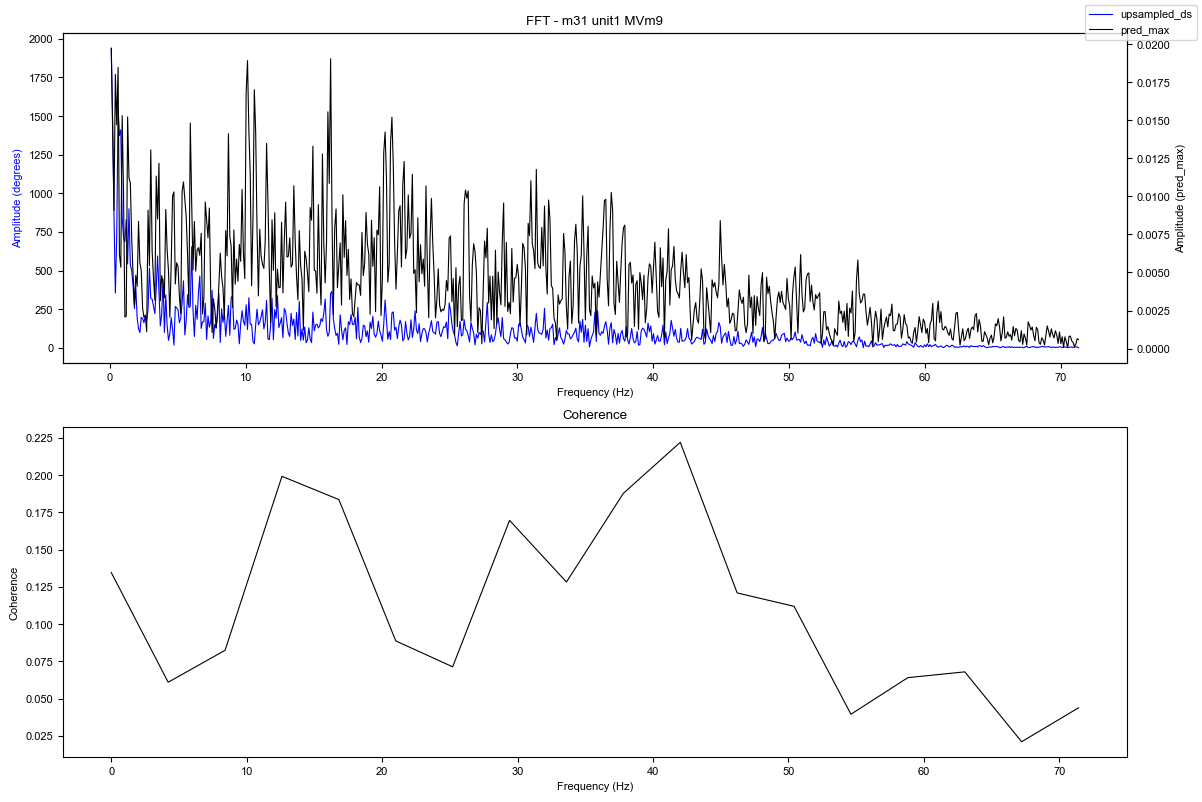

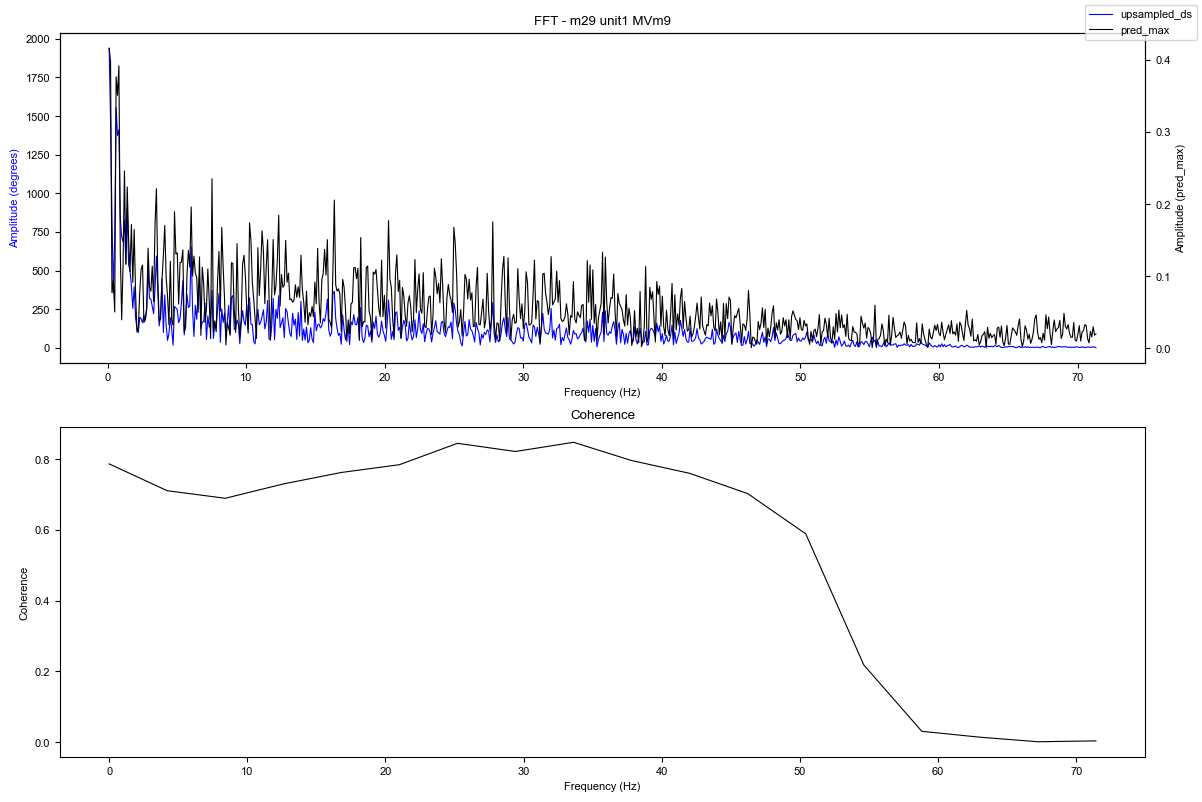

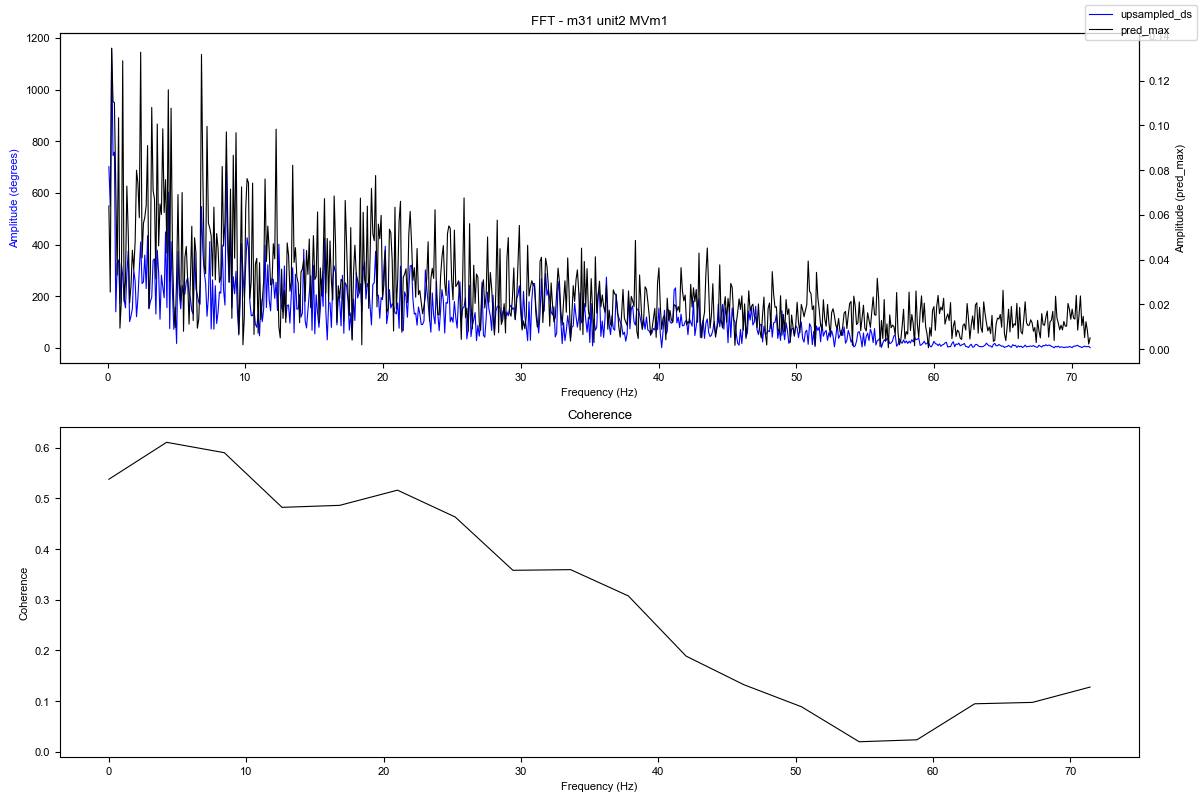

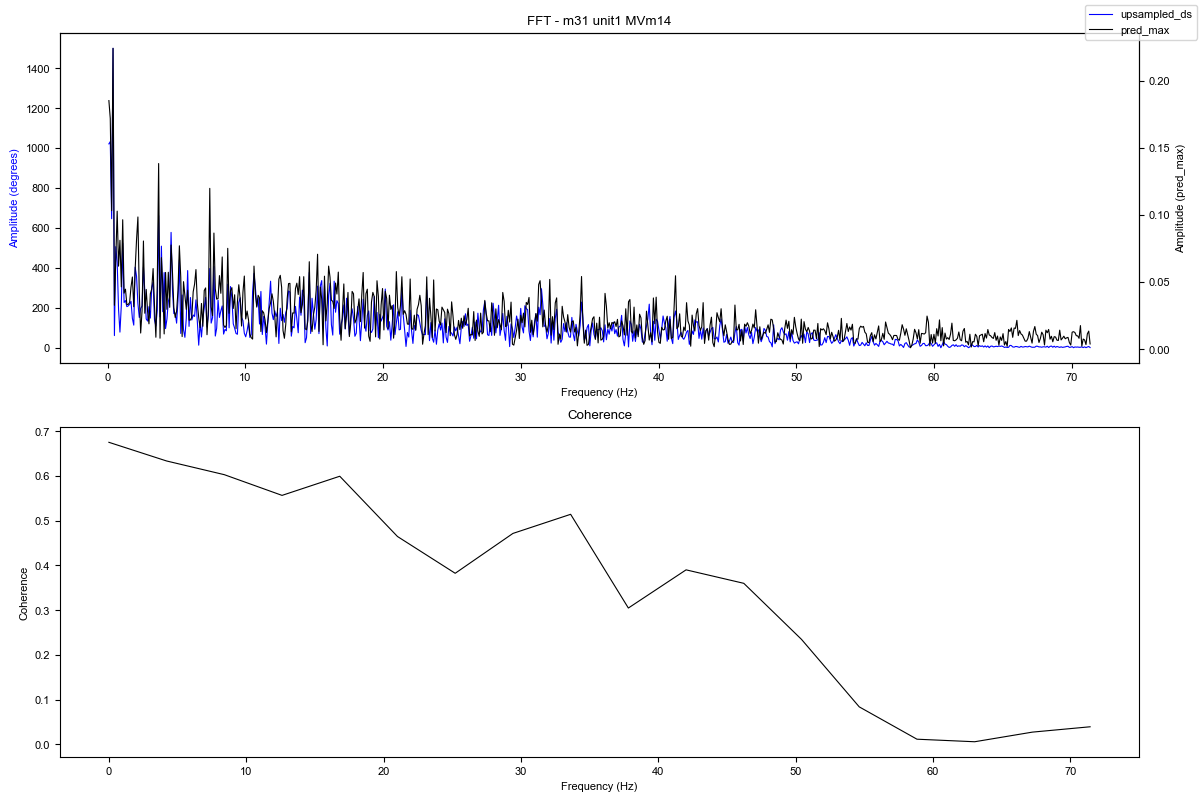

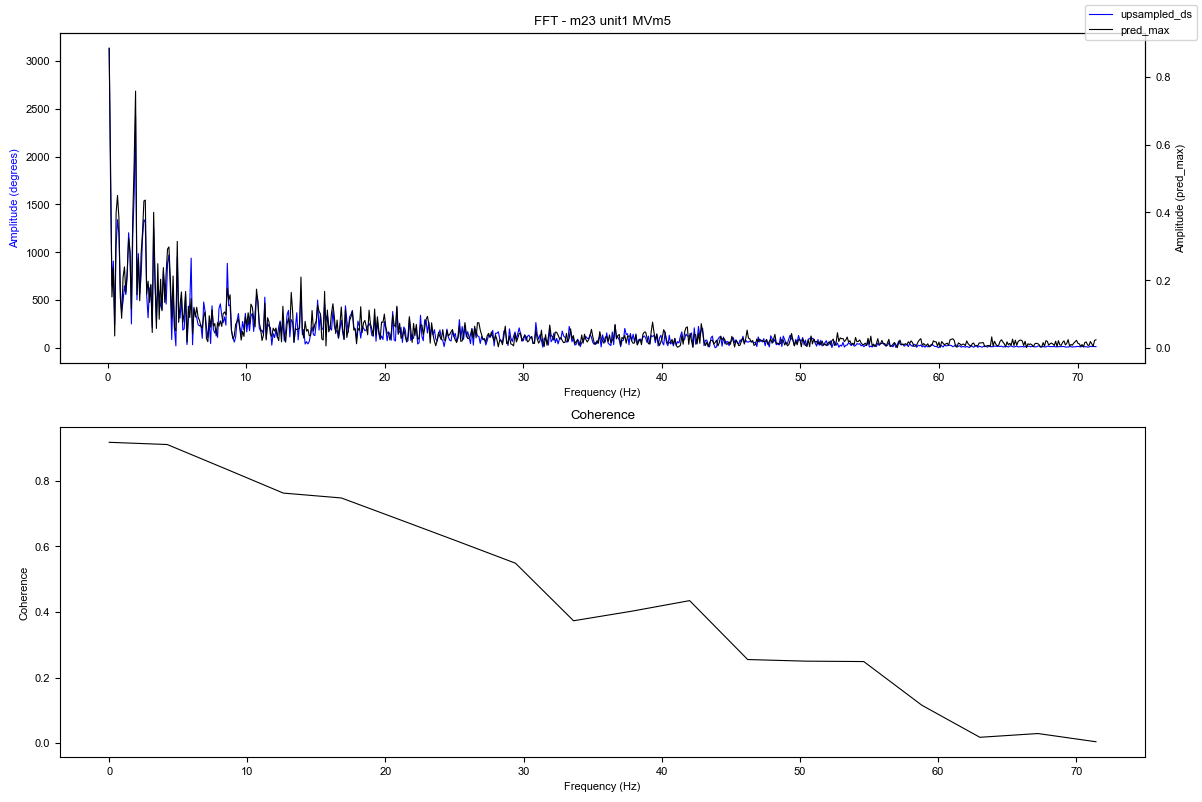

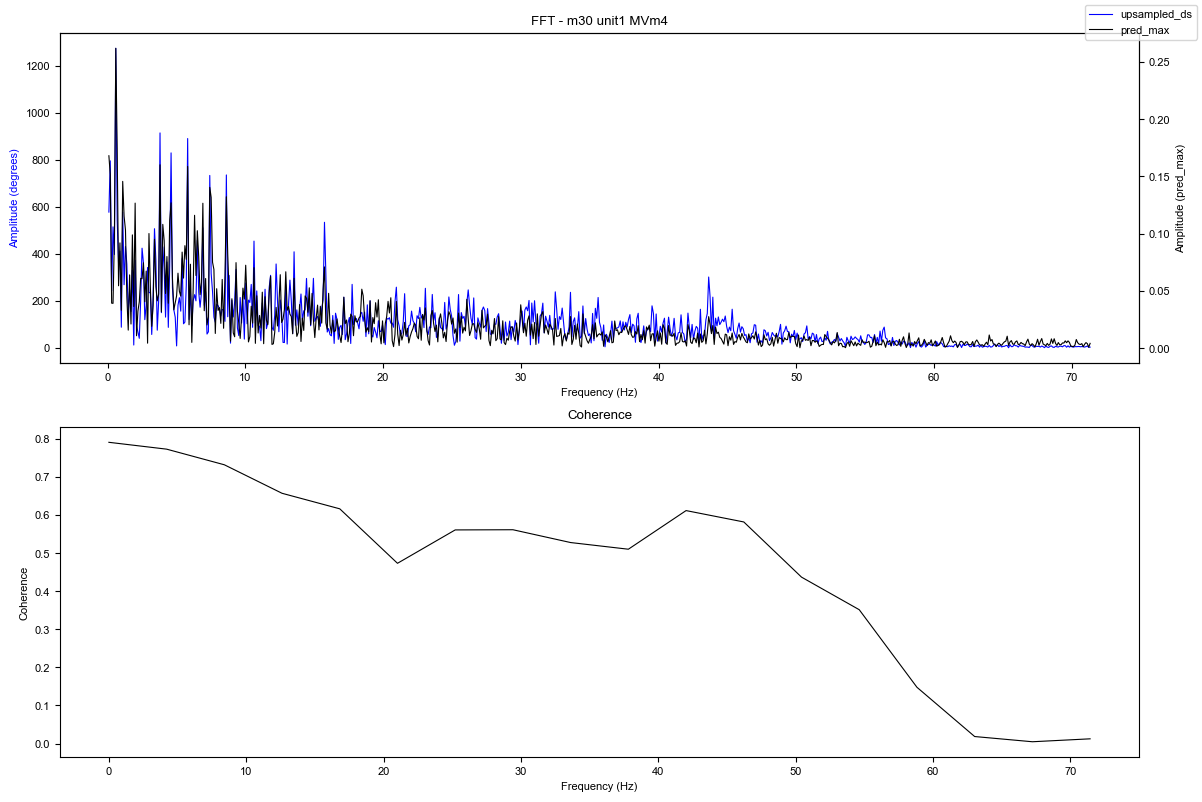

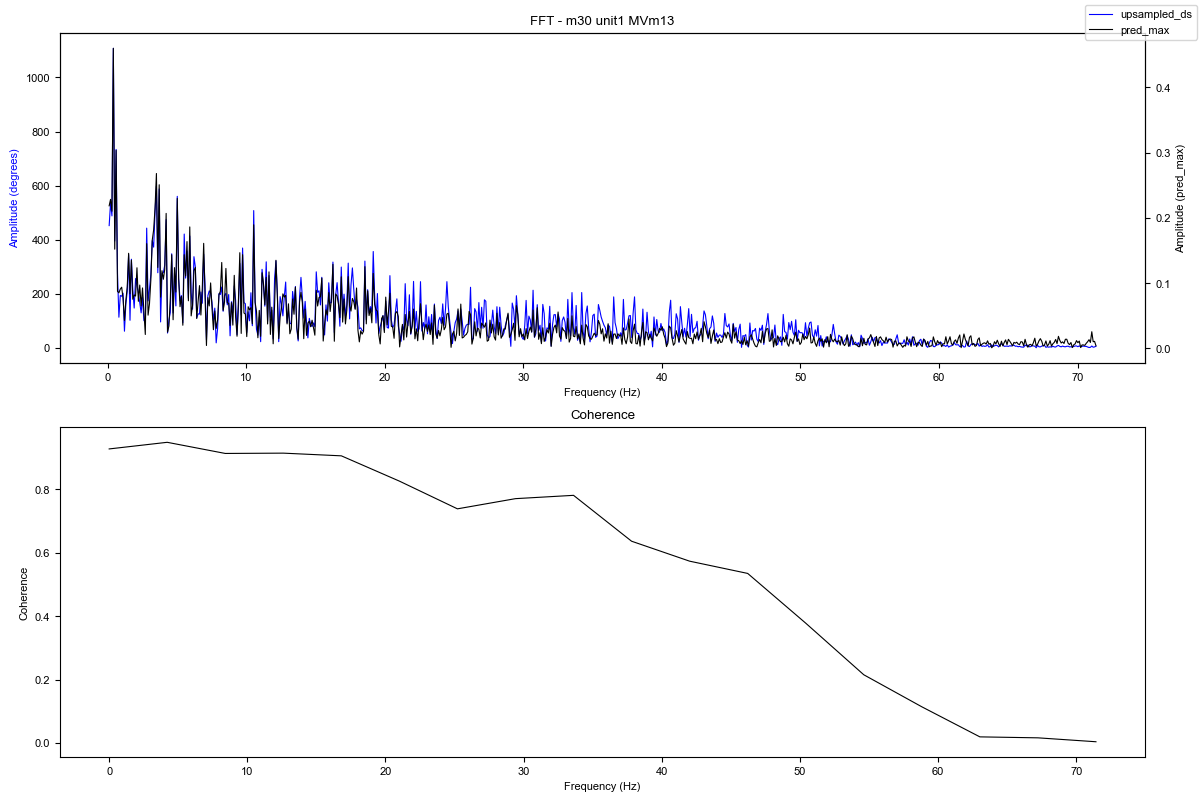

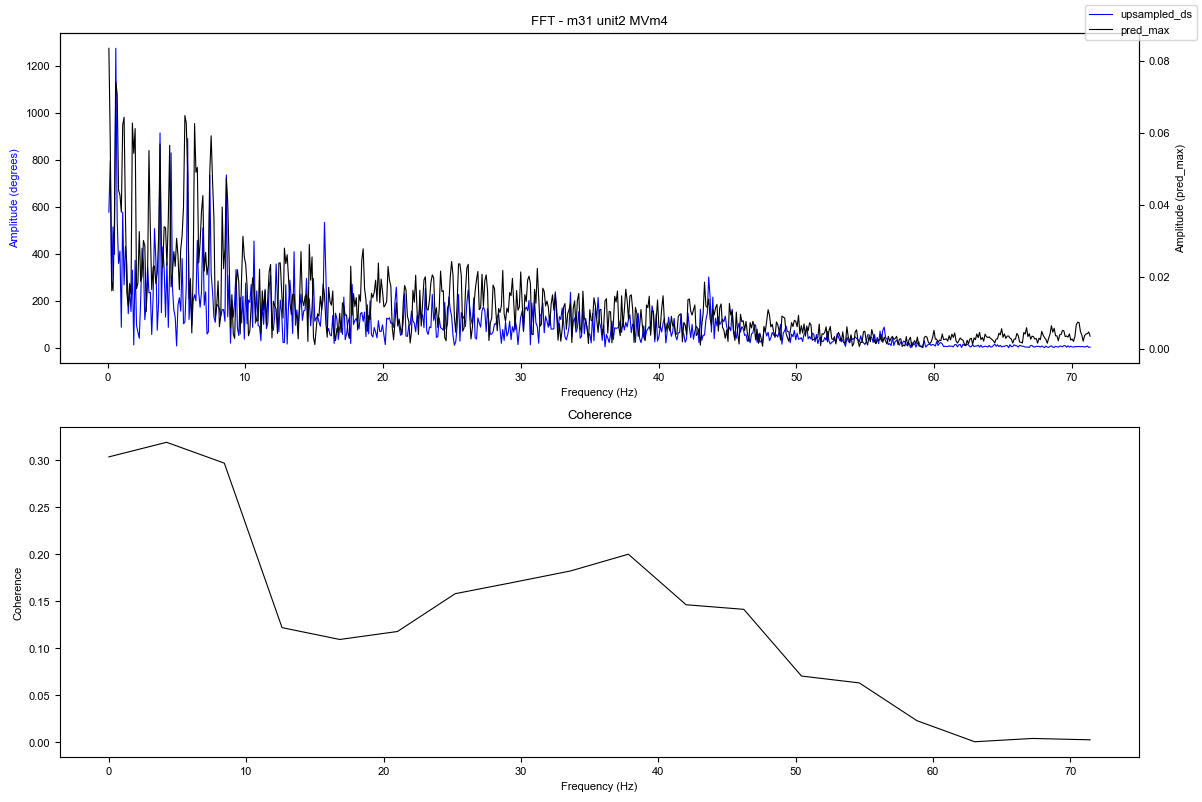

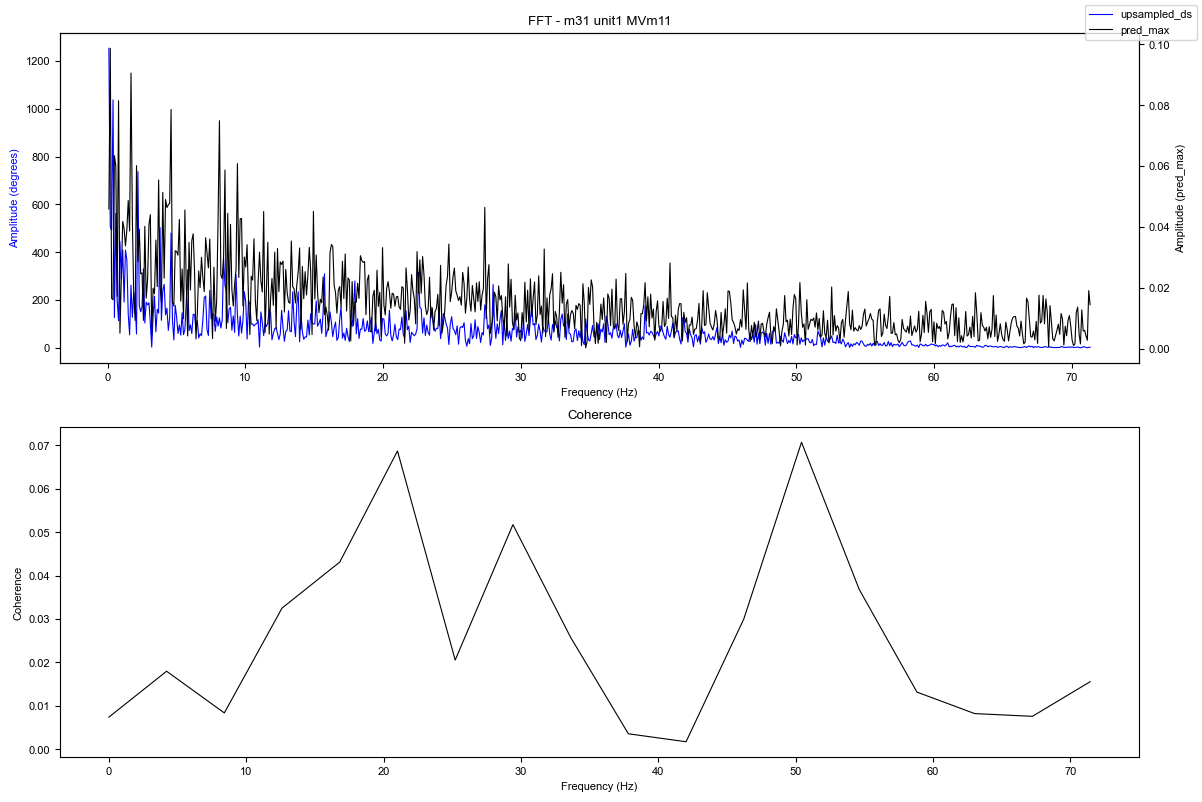

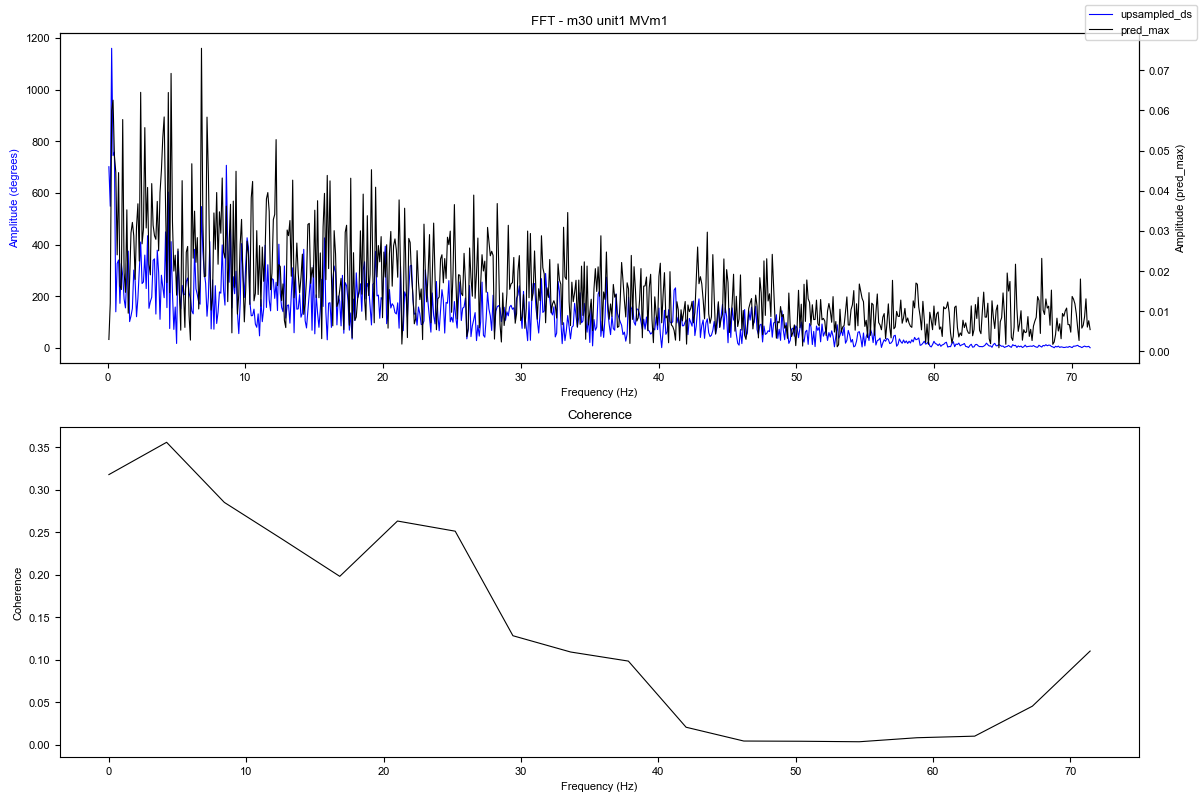

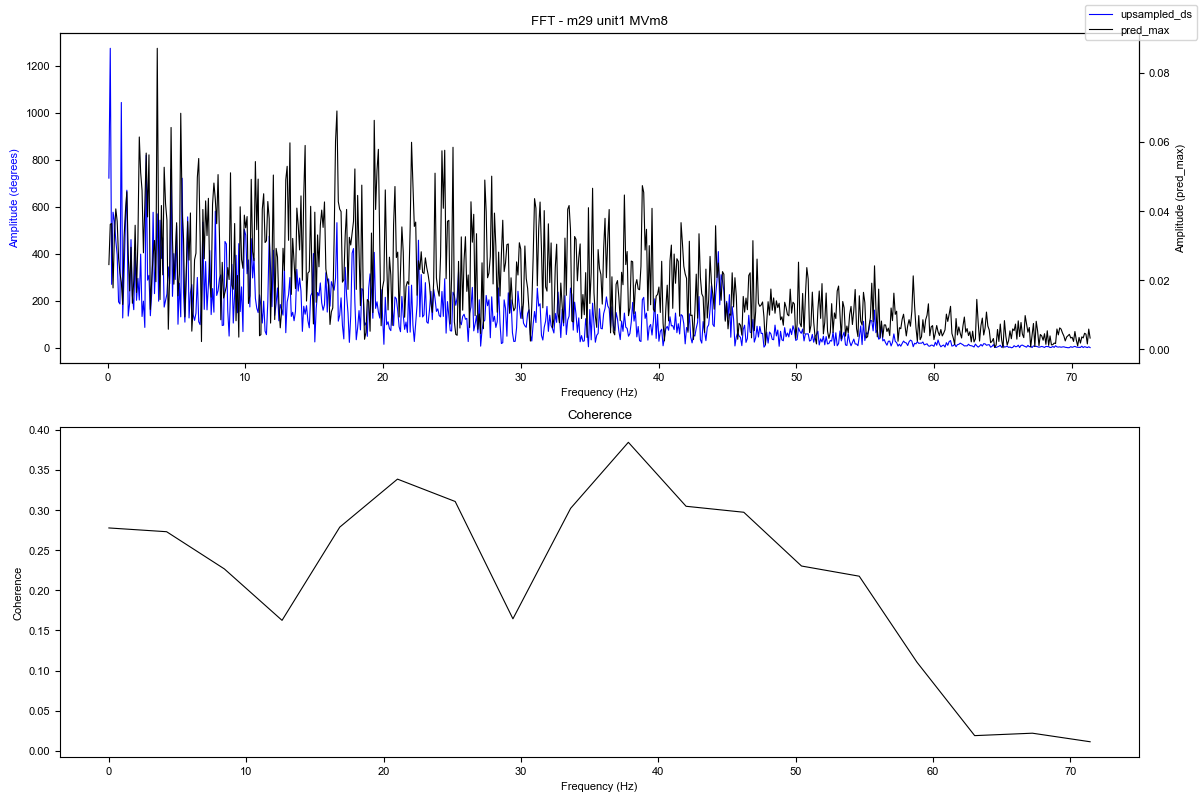

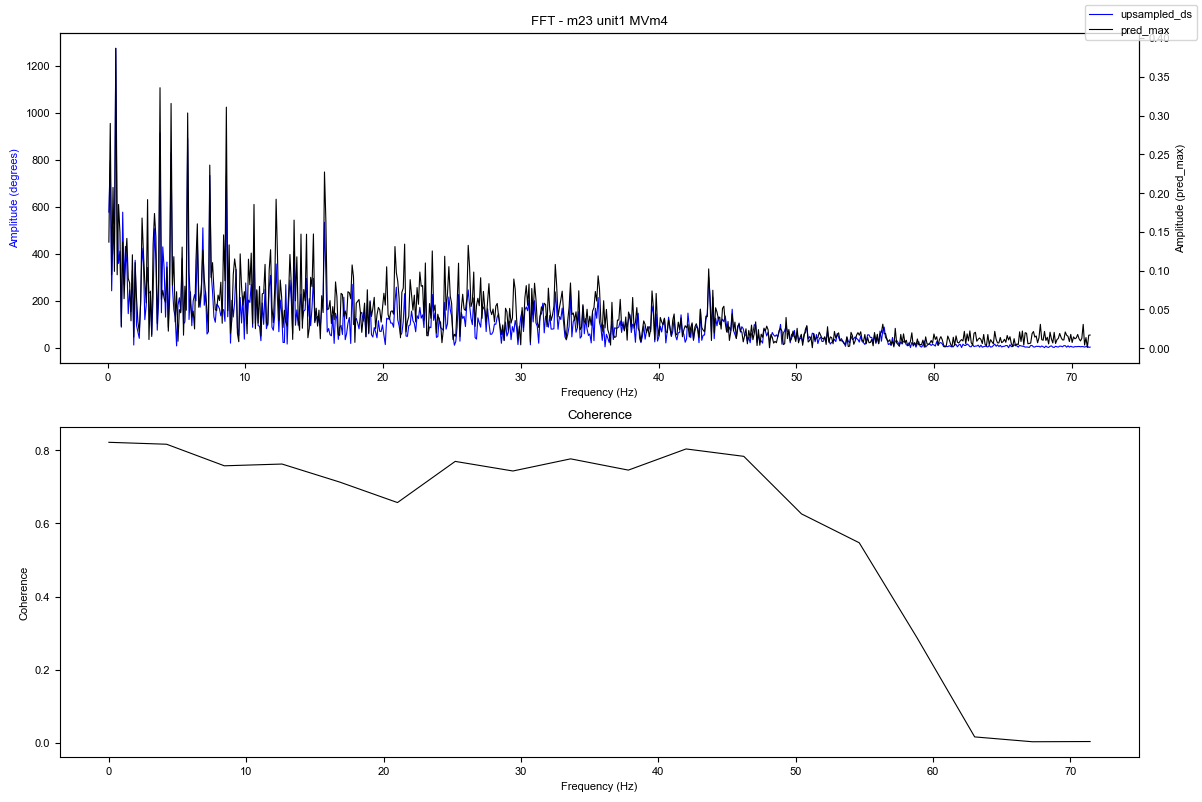

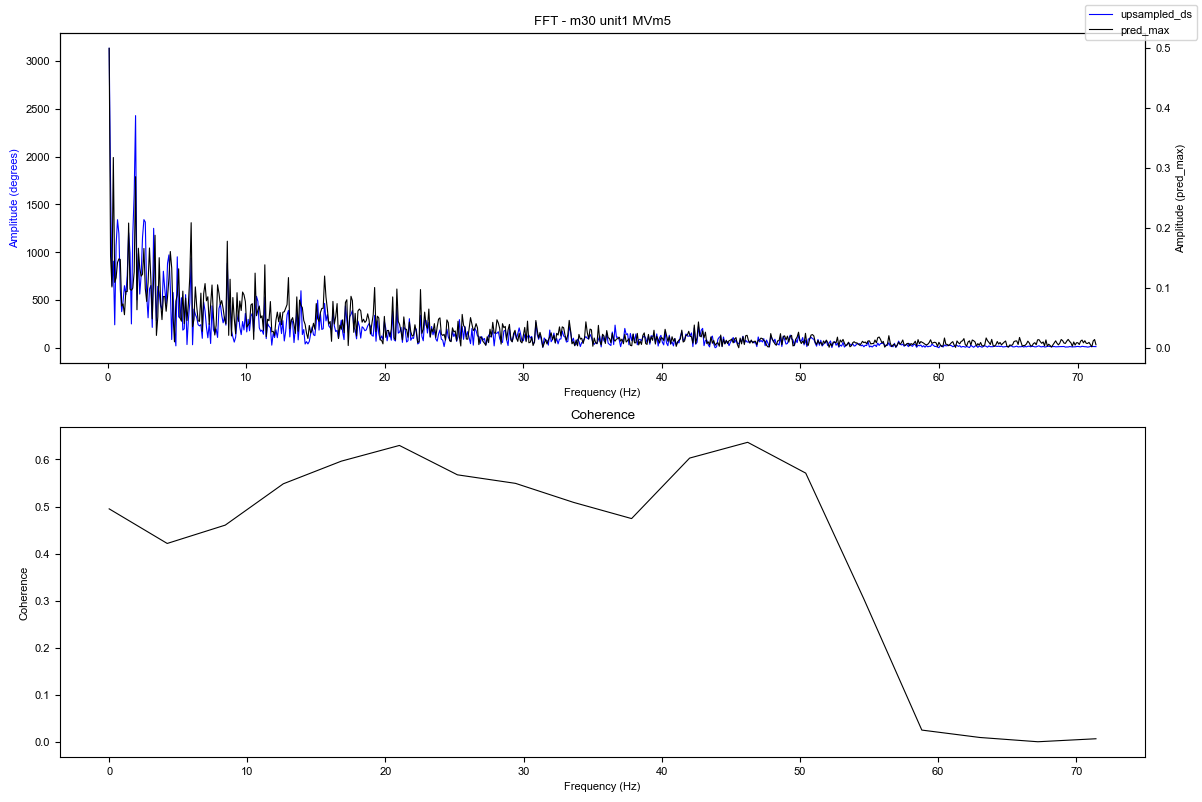

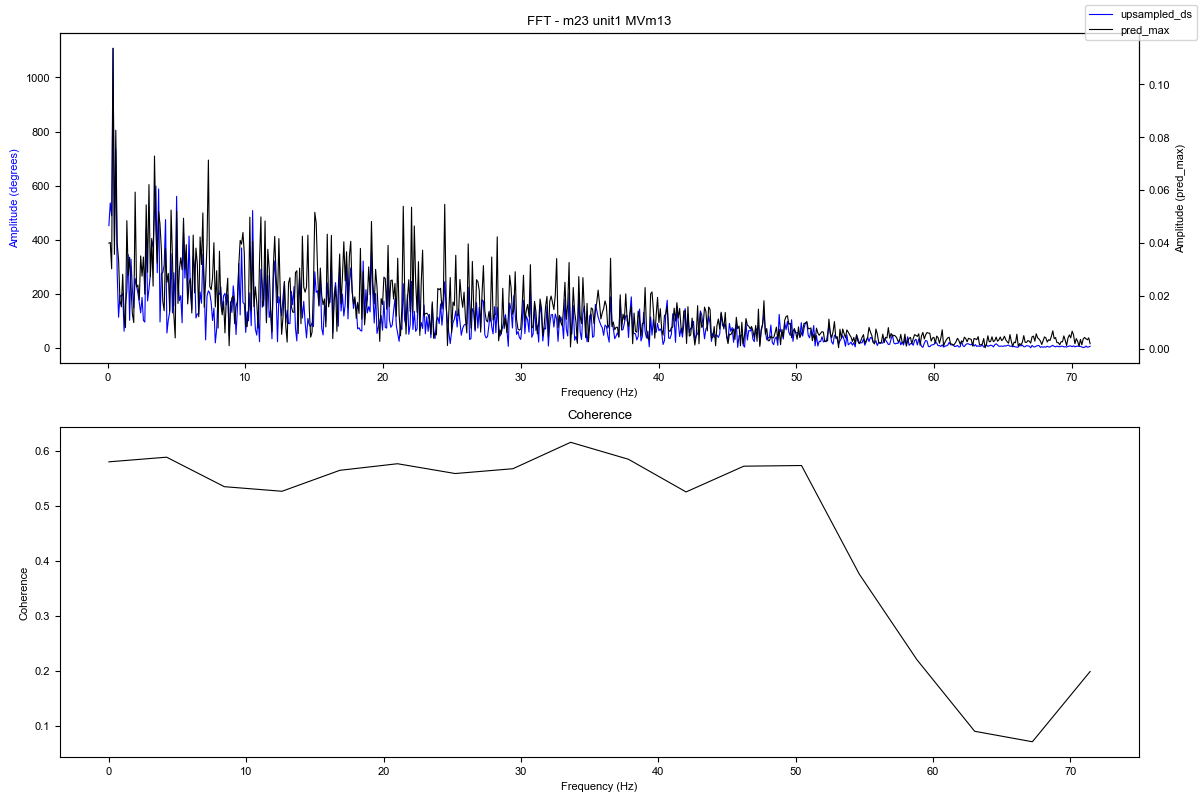

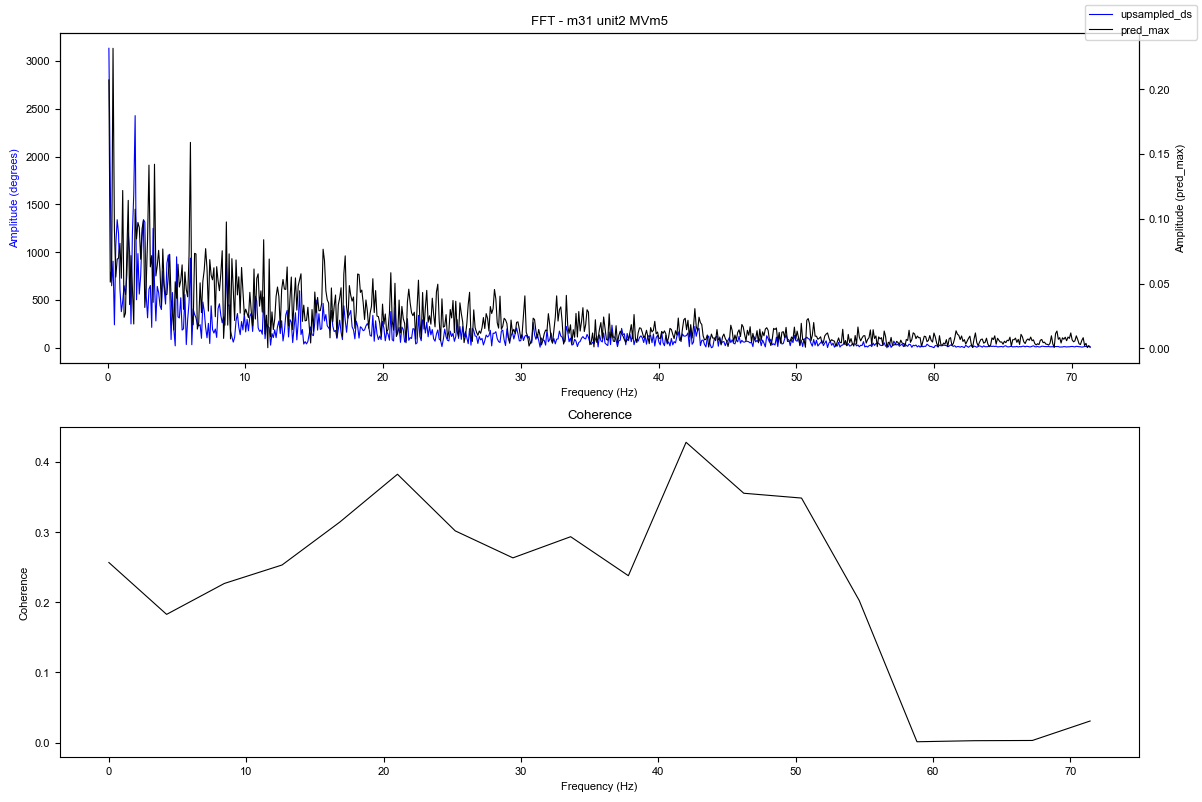

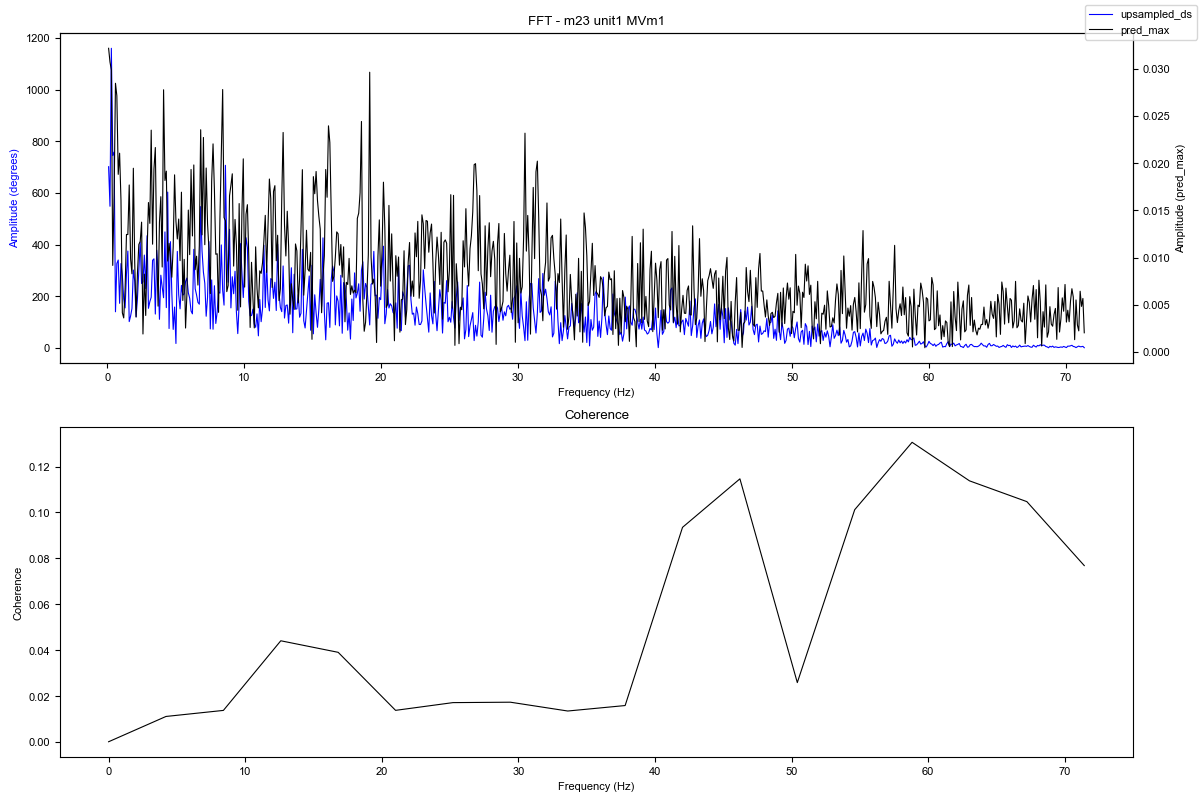

In [18]:
chunk_size = 210

for filepath in prediction_files:
    with open(filepath, 'rb') as f:
        savedData = pickle.load(f)
    moth     = os.path.basename(filepath).split('_')[0]
    unitID   = os.path.basename(filepath).split('_')[1]
    vid_moth = os.path.basename(filepath).split('_')[3]

    df_proj   = savedData[2]
    upsampled = savedData[3]
    upsampled_ds = upsampled[:len(upsampled)//chunk_size * chunk_size].reshape(-1, chunk_size).mean(axis=1)
    p_spike = df_proj['pred_max'].values[::chunk_size]
    min_len = min(len(p_spike), len(upsampled_ds))
    p_spike = p_spike[:min_len]
    upsampled_ds = upsampled_ds[:min_len]

    n = len(p_spike)
    freqs = fftfreq(n, d=1/(Fs/chunk_size))
    pos = freqs > 0

    fft_pred      = np.abs(fft(p_spike - np.mean(p_spike)))[pos]
    fft_upsampled = np.abs(fft(upsampled_ds - np.mean(upsampled_ds)))[pos]
    freqs_pos     = freqs[pos]

    #f, Cxy = coherence(p_spike, upsampled_ds, fs=Fs/chunk_size)
    f, Cxy = coherence(p_spike, upsampled_ds, fs=Fs/chunk_size, nperseg=34)
    #cross_spectrum = np.abs(fft(p_spike - np.mean(p_spike)) * np.conj(fft(upsampled_ds - np.mean(upsampled_ds))))[pos]

    fig, axes = plt.subplots(2, 1, figsize=(12, 8))

    ax2 = axes[0].twinx()
    axes[0].plot(freqs_pos, fft_upsampled, 'blue', linewidth=0.8, label='upsampled_ds')
    axes[0].set_ylabel('Amplitude (degrees)', color='blue')
    ax2.plot(freqs_pos, fft_pred, 'k', linewidth=0.8, label='pred_max')
    ax2.set_ylabel('Amplitude (pred_max)', color='black')
    axes[0].set_xlabel('Frequency (Hz)')
    axes[0].set_title(f'FFT - {moth} {unitID} {vid_moth}')
    fig.legend(loc='upper right')


    axes[1].plot(f, Cxy, 'k', linewidth=0.8)
    axes[1].set_title('Coherence')
    axes[1].set_ylabel('Coherence')
    axes[1].set_xlabel('Frequency (Hz)')

    plt.tight_layout()
    #plt.savefig(out_fig + moth + '_' + unitID + '_' + vid_moth + '_fft_coherence.pdf')  
    plt.show()
    plt.close()

In [ ]:
summary_df = pd.DataFrame(summary_rows)
print(summary_df)
summary_df.to_excel(out_path + 'crosscor_coherence_summary.xlsx', index=False)
print(f'saved to {out_path}crosscor_coherence_summary.xlsx')

In [ ]:
# for key, vals in sorted(crosscor_results.items(), key=lambda x: x[0]):
# #     print(f"{key}: peak={vals['crosscor_peak']:.3f} at lag={vals['crosscor_peak_lag_s']:.4f}s | at_zero={vals['crosscor_at_zero']:.3f}")

In [ ]:
#Fs = 3e4
# t = np.arange(0, 10, 1/Fs)  # 10 seconds at 30kHz

# signal = np.sin(2 * np.pi * 5 * t) + \
#          np.sin(2 * np.pi * 20 * t) + \
#          np.sin(2 * np.pi * 50 * t)

# n = len(signal)
# freqs = fftfreq(n, d=1/Fs)
# pos = freqs > 0
# fft_signal = np.abs(fft(signal))[pos]
# freqs_pos = freqs[pos]

# plt.figure(figsize=(12, 3))
# plt.plot(freqs_pos, fft_signal, 'k', linewidth=0.8)
# plt.xlim(0, 70)
# plt.xlabel('Frequency (Hz)')
# plt.ylabel('Amplitude')
# plt.title('FFT of sum of sines test (5Hz + 20Hz + 50Hz)')
# plt.show()